<a href="https://colab.research.google.com/github/FionaMacapulay/cs138capstone/blob/main/Modeling_Fuel_Price_Shocks_and_Inflation_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modeling Fuel-Price Shocks and Inflation in the Philippines
**CS 138 Capstone (C2: Economics)** — 1st Semester, A.Y. 2026–2027

| Name | Student ID | Contribution (Part A / Part B / Part C / writing) |
|---|---|---|
| Alberto, Ariz Joshua | 2024-06504 | _TODO_ |
| Chen, Jim | 2023-14385 | _TODO_ |
| Gawat, Kyle Lorenz | 2024-02966 | _TODO_ |
| Macapulay, Fiona | 2024-02095 | _TODO_ |
| Laab, Clint Gerard | 2024-00193 | _TODO_ |

> **Reproducibility.** Run *Restart & Run all*. PSA sheets are cached in `data_cache/` (commit that folder); the geoBoundaries
> polygons are fetched at run time — if that fails the spatial cells stop with an error instead of silently using a schematic mask.
> **v2 changes:** local data cache; north-up fallback mask; hub seeds from lat/lon; new sections 9–15 (conservative solver,
> regional calibration, A↔B coupling, implicit schemes, resolution study). Earlier cell outputs are from v1 — re-run everything.

## **Algorithm Overview**
### **Phase A — Numerical Linear Algebra (Least Squares Pass-Through)**
- Formulate overdetermined linear systems $A\boldsymbol{\beta} \approx \mathbf{y}$ on Month-on-Month (MoM) percentage changes for Headline CPI ($\mathbf{y}$) from Liquid Fuels ($F$), Gas/LPG ($G$), and Electricity ($E$).

- Compare three solvers on an $80\% / 20\%$ chronological train/test split:
  1. Reduced QR Factorization: $A = QR \implies R\boldsymbol{\beta} = Q^T\mathbf{y}$ via back-substitution.
  2. Normal Equations via Cholesky: $A^T A \boldsymbol{\beta} = A^T\mathbf{y}$, $A^T A = LL^T$, solved via forward/backward substitution.
  3. Thin Singular Value Decomposition (SVD): $A = U\Sigma V^T \implies \boldsymbol{\beta} = V\Sigma^{-1}U^T\mathbf{y}$.

- Track condition numbers $\kappa_2(A)$ vs. $\kappa_2(A^T A)$, solver differences, in-sample/out-of-sample RMSE, MAE, and $R^2$, plus a lag stress-test ($k = 0 \dots 6$) and regional pass-through estimates $\beta_{1,r}$.

### **Phase B — Numerical PDEs (2D Reaction-Diffusion on Philippine Domain):**
- Solve the 2D reaction-diffusion equation over a rasterized Philippine land mask $\Omega_{\text{PHL}}$:

  $$\frac{\partial u}{\partial t} = D\left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right) - \alpha u$$

- Advance in time using an explicit Forward-Time Central-Space (FTCS) 5-point Laplacian stencil under a Courant–Friedrichs–Lewy (CFL) stability time-step bound, with zero-flux Neumann boundaries on land coasts and Dirichlet/absorbing exterior conditions.

- Verify against a known analytical solution on $[0,1]^2$ with spatial grid refinement ($O(\Delta x^2)$ order check) and compare $D=0$ (no diffusion) vs. $D>0$ and parameter sweeps ($D, \alpha$).

## **Configuration and Dependencies**

In [ ]:
import os
import re
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.linalg import cho_factor, cho_solve, qr, svd

warnings.filterwarnings("ignore", category=UserWarning)

# Optional geospatial imports (graceful fallback if unavailable)
try:
  import geopandas as gpd

  HAS_GEOPANDAS = True
except ImportError:
  HAS_GEOPANDAS = False

try:
  from rasterio import features
  from affine import Affine

  HAS_RASTERIO = True
except ImportError:
  HAS_RASTERIO = False

# Global plot styling
plt.rcParams.update({
    "figure.dpi": 140,
    "font.sans-serif": "Liberation Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ==============================================================================
# CENTRAL CONFIGURATION & CONSTANTS
# ==============================================================================
SHEET_ID = "16wHIrbgpTxLYHlVMSEemRzGD76857RVkXBFVs0IGnYM"
ENERGY_CPI_GID = 1114954719
HEADLINE_CPI_GID = 233514125

DATE_START = "2018-01-01"
DATE_END = "2026-10-01"
TRAIN_RATIO = 0.80

ENERGY_COLS = ["Liquid Fuels", "Gas", "Electricity"]
ALL_SERIES_COLS = ["Liquid Fuels", "Gas", "Electricity", "Headline_CPI"]
VALID_MONTHS = {
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
}

MAIN_REGIONS = [
    "National Capital Region (NCR)",
    "Cordillera Administrative Region (CAR)",
    "Region I (Ilocos Region)",
    "Region II (Cagayan Valley)",
    "Region III (Central Luzon)",
    "Region IV-A (CALABARZON)",
    "MIMAROPA Region",
    "Region V (Bicol Region)",
    "Region VI (Western Visayas)",
    "Region VII (Central Visayas)",
    "Region VIII (Eastern Visayas)",
    "Region IX (Zamboanga Peninsula)",
    "Region X (Northern Mindanao)",
    "Region XI (Davao Region)",
    "Region XII (SOCCSKSARGEN)",
    "Region XIII (Caraga)",
    "Bangsamoro Autonomous Region in Muslim Mindanao (BARMM)",
    "Negros Island Region (NIR)",
]

SHORT_NAMES = {
    "National Capital Region (NCR)": "NCR",
    "Cordillera Administrative Region (CAR)": "CAR",
    "Region I (Ilocos Region)": "Region I (Ilocos)",
    "Region II (Cagayan Valley)": "Region II (Cagayan)",
    "Region III (Central Luzon)": "Region III (C. Luzon)",
    "Region IV-A (CALABARZON)": "Region IV-A (CALABARZON)",
    "MIMAROPA Region": "MIMAROPA",
    "Region V (Bicol Region)": "Region V (Bicol)",
    "Region VI (Western Visayas)": "Region VI (W. Visayas)",
    "Negros Island Region (NIR)": "NIR (Est. 2024)",
    "Region VII (Central Visayas)": "Region VII (C. Visayas)",
    "Region VIII (Eastern Visayas)": "Region VIII (E. Visayas)",
    "Region IX (Zamboanga Peninsula)": "Region IX (Zamboanga)",
    "Region X (Northern Mindanao)": "Region X (N. Mindanao)",
    "Region XI (Davao Region)": "Region XI (Davao)",
    "Region XII (SOCCSKSARGEN)": "Region XII (SOCCSKSARGEN)",
    "Region XIII (Caraga)": "Region XIII (Caraga)",
    "Bangsamoro Autonomous Region in Muslim Mindanao (BARMM)": "BARMM",
}

## **Data Parsing & Variable Organization**
This cell parses both the Energy CPI tab and the Headline CPI tab cleanly, filters out footnotes/averages/blank columns, and organizes national and regional level + MoM % DataFrames into consistent dictionaries.

In [ ]:
import hashlib
DATA_DIR = "data_cache"          # commit this folder with the notebook


def cached_read_csv(url, name, **kw):
  """Download once, then always read the local copy (the Google Sheet may change)."""
  os.makedirs(DATA_DIR, exist_ok=True)
  path = os.path.join(DATA_DIR, name)
  if not os.path.exists(path):
    df_ = pd.read_csv(url, **kw)
    df_.to_csv(path, index=False, header=kw.get("header", "infer") is not None)
  with open(path, "rb") as fh:
    print(f"[data] {name}: sha256 {hashlib.sha256(fh.read()).hexdigest()[:12]}")
  return pd.read_csv(path, **kw)


def _extract_month_columns(columns):
  """Returns ordered valid 'Mon YYYY' column labels, excluding 'Ave' or blank cols."""
  valid_cols = []
  for c in columns:
    s = str(c).strip()
    m = re.match(r"^([A-Za-z]{3})\s+(\d{4})$", s)
    if m and m.group(1).title() in VALID_MONTHS:
      valid_cols.append(c)
  return valid_cols


def load_psa_wide_sheet(sheet_id, gid, drop_leading_spacer=True):
  """Loads a PSA OpenSTAT Google Sheet tab and normalizes Region/Commodity/Month cols."""
  url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}"
  df_raw = cached_read_csv(url, f"psa_gid_{gid}.csv", header=None)

  if drop_leading_spacer and df_raw.shape[1] > 2:
    # Only drop col 0 if it looks like an empty spacer or row number column
    first_col_non_null = df_raw.iloc[:, 0].notna().sum()
    if first_col_non_null < 5:
      df_raw = df_raw.iloc[:, 1:].reset_index(drop=True)

  # Locate header row containing a 'Mon 2018' label
  header_mask = df_raw.apply(
      lambda r: r.astype(str).str.contains(r"\bJan\s+2018\b", regex=True).any(),
      axis=1,
  )
  if not header_mask.any():
    raise ValueError(f"Could not locate 'Jan 2018' header row in gid={gid}.")
  header_idx = header_mask.idxmax()

  header_vals = df_raw.iloc[header_idx].astype(str).str.strip().tolist()
  header_vals[0] = "Region"
  header_vals[1] = "Commodity"
  # Disambiguate any duplicate column names before indexing
  seen = {}
  unique_cols = []
  for col_name in header_vals:
    count = seen.get(col_name, 0)
    unique_cols.append(col_name if count == 0 else f"{col_name}_{count}")
    seen[col_name] = count + 1

  body = df_raw.iloc[header_idx + 1 :].copy()
  body.columns = unique_cols

  body["Region"] = (
      body["Region"]
      .replace(["nan", "None", ""], np.nan)
      .ffill()
      .astype(str)
      .str.replace(r"\s+", " ", regex=True)
      .str.strip()
  )
  body["Commodity"] = body["Commodity"].astype(str).str.strip()

  month_cols = _extract_month_columns(body.columns[2:])
  return body, month_cols


def parse_series_for_location(df_body, location, commodities, month_cols):
  """Extracts a sorted datetime-indexed numeric DataFrame for a single location."""
  sub = df_body[
      (df_body["Region"] == location) & (df_body["Commodity"].isin(commodities))
  ]
  if sub.empty:
    return pd.DataFrame()
  # Deduplicate by Commodity in case repeated rows exist
  sub = sub.drop_duplicates(subset=["Commodity"], keep="first")
  ts = sub.set_index("Commodity")[month_cols].T
  ts.index = pd.to_datetime(ts.index, format="%b %Y")
  ts.index.name = "Date"
  ts = ts.replace("..", np.nan).apply(pd.to_numeric, errors="coerce")
  return ts.sort_index().loc[DATE_START:DATE_END]


# 1. Parse Energy CPI (Liquid Fuels, Gas, Electricity)
energy_body, energy_months = load_psa_wide_sheet(
    SHEET_ID, ENERGY_CPI_GID, drop_leading_spacer=True
)

df_ph_levels = parse_series_for_location(
    energy_body, "PHILIPPINES", ENERGY_COLS, energy_months
)
region_levels = {}
active_regions = []

for reg in MAIN_REGIONS:
  reg_ts = parse_series_for_location(
      energy_body, reg, ENERGY_COLS, energy_months
  )
  if not reg_ts.empty:
    region_levels[reg] = reg_ts
    active_regions.append(reg)

# 2. Parse Headline CPI ('0 - ALL ITEMS') and merge
cpi_body, cpi_months = load_psa_wide_sheet(
    SHEET_ID, HEADLINE_CPI_GID, drop_leading_spacer=False
)
ph_cpi_df = parse_series_for_location(
    cpi_body, "PHILIPPINES", ["0 - ALL ITEMS"], cpi_months
)
if not ph_cpi_df.empty:
  df_ph_levels["Headline_CPI"] = ph_cpi_df["0 - ALL ITEMS"].reindex(
      df_ph_levels.index
  )

for reg in active_regions:
  reg_cpi_df = parse_series_for_location(
      cpi_body, reg, ["0 - ALL ITEMS"], cpi_months
  )
  if not reg_cpi_df.empty:
    region_levels[reg]["Headline_CPI"] = reg_cpi_df["0 - ALL ITEMS"].reindex(
        region_levels[reg].index
    )

# 3. Compute Month-on-Month (MoM %) changes for National and Regional datasets
available_ph_cols = [c for c in ALL_SERIES_COLS if c in df_ph_levels.columns]
df_ph_mom = (df_ph_levels[available_ph_cols].pct_change() * 100.0).dropna(
    how="all"
)

region_mom = {}
for reg in active_regions:
  avail_r_cols = [
      c for c in ALL_SERIES_COLS if c in region_levels[reg].columns
  ]
  region_mom[reg] = region_levels[reg][avail_r_cols].pct_change() * 100.0

print(
    f"National levels shape : {df_ph_levels.shape}"
    f" ({df_ph_levels.index.min().strftime('%b %Y')} –"
    f" {df_ph_levels.index.max().strftime('%b %Y')})"
)
print(
    f"National MoM shape    : {df_ph_mom.shape}"
    f" ({df_ph_mom.index.min().strftime('%b %Y')} –"
    f" {df_ph_mom.index.max().strftime('%b %Y')})"
)
print(f"Active regions loaded : {len(active_regions)}")

[data] psa_gid_1114954719.csv: sha256 9be0612ebea4
[data] psa_gid_233514125.csv: sha256 62df4a286fe7
National levels shape : (106, 4) (Jan 2018 – Oct 2026)
National MoM shape    : (105, 4) (Feb 2018 – Oct 2026)
Active regions loaded : 18


## **Phase A — NLA Least Squares Regression, Solvers & Stress Tests**

This cell defines the three NLA solvers (`QR`, `Cholesky`, `SVD`), benchmarks Models 1–3 on an $80\% / 20\%$ chronological split, runs the lag multicollinearity stress-test ($k = 0 \dots 6$), and computes regional pass-through slopes $\beta_{1,r}$.

In [ ]:
def solve_qr(A, b):
  """Least squares via Reduced QR factorization (A = Q R -> R beta = Q^T b)."""
  Q, R = qr(A, mode="economic")
  return np.linalg.solve(R, Q.T @ b)


def solve_cholesky(A, b):
  """Least squares via Normal Equations (A^T A beta = A^T b) with Cholesky."""
  ATA = A.T @ A
  ATb = A.T @ b
  c_fac, lower = cho_factor(ATA, lower=True)
  return cho_solve((c_fac, lower), ATb)


def solve_svd(A, b):
  """Least squares via Thin SVD (A = U S V^T -> beta = V S^{-1} U^T b)."""
  U, s, Vt = svd(A, full_matrices=False)
  tol = np.finfo(float).eps * max(A.shape) * (s[0] if len(s) > 0 else 1.0)
  s_inv = np.where(s > tol, 1.0 / s, 0.0)
  return Vt.T @ (s_inv * (U.T @ b))


def regression_metrics(y_true, y_pred):
  """Computes RMSE, MAE, and R^2."""
  err = y_true - y_pred
  rmse = float(np.sqrt(np.mean(err**2)))
  mae = float(np.mean(np.abs(err)))
  ss_res = float(np.sum(err**2))
  ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
  r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0 else np.nan
  return rmse, mae, r2


def build_lagged_frame(df_mom_in, max_lag=1, target_col="Headline_CPI"):
  """Builds a clean lagged DataFrame with contemporaneous (t-0) through t-max_lag."""
  out = pd.DataFrame(index=df_mom_in.index)
  out[target_col] = df_mom_in[target_col]
  feature_cols = []
  for lag in range(max_lag + 1):
    for col in ENERGY_COLS:
      feat_name = col if lag == 0 else f"{col}_lag{lag}"
      out[feat_name] = df_mom_in[col].shift(lag)
      feature_cols.append(feat_name)
  return out.dropna(), feature_cols


# 1. Align N = 104 sample (Mar 2018 – Oct 2026) across Baseline, Lag-1, and Dist-Lag
df_aligned, _ = build_lagged_frame(df_ph_mom, max_lag=1, target_col="Headline_CPI")
n_total = len(df_aligned)
n_train = int(np.floor(n_total * TRAIN_RATIO))
train_df = df_aligned.iloc[:n_train]
test_df = df_aligned.iloc[n_train:]

model_specs = {
    "1. Baseline (t)": ["Liquid Fuels", "Gas", "Electricity"],
    "2. Lagged (t-1)": ["Liquid Fuels_lag1", "Gas_lag1", "Electricity_lag1"],
    "3. Distributed Lag (t, t-1)": [
        "Liquid Fuels",
        "Gas",
        "Electricity",
        "Liquid Fuels_lag1",
        "Gas_lag1",
        "Electricity_lag1",
    ],
}

phase_a_rows = []
fitted_phase_a = {}

for m_name, x_cols in model_specs.items():
  A_tr = np.column_stack([np.ones(len(train_df)), train_df[x_cols].values])
  A_te = np.column_stack([np.ones(len(test_df)), test_df[x_cols].values])
  b_tr = train_df["Headline_CPI"].values
  b_te = test_df["Headline_CPI"].values

  beta_qr = solve_qr(A_tr, b_tr)
  beta_chol = solve_cholesky(A_tr, b_tr)
  beta_svd = solve_svd(A_tr, b_tr)
  fitted_phase_a[m_name] = (beta_qr, x_cols)

  cond_A = np.linalg.cond(A_tr)
  cond_ATA = np.linalg.cond(A_tr.T @ A_tr)

  tr_rmse, tr_mae, tr_r2 = regression_metrics(b_tr, A_tr @ beta_qr)
  te_rmse, te_mae, te_r2 = regression_metrics(b_te, A_te @ beta_qr)

  phase_a_rows.append({
      "Model": m_name,
      "kappa(A)": round(cond_A, 4),
      "kappa(A^T A)": round(cond_ATA, 4),
      "||Chol - SVD||_2": f"{np.linalg.norm(beta_chol - beta_svd):.2e}",
      "||QR - SVD||_2": f"{np.linalg.norm(beta_qr - beta_svd):.2e}",
      "Train RMSE": round(tr_rmse, 4),
      "Train R^2": round(tr_r2, 4),
      "Test RMSE": round(te_rmse, 4),
      "Test MAE": round(te_mae, 4),
      "Test R^2": round(te_r2, 4),
  })

phase_a_df = pd.DataFrame(phase_a_rows)

# 2. Lag Multicollinearity Stress-Test (k = 0..6)
lag_stress_rows = []
for k in range(7):
  df_k, cols_k = build_lagged_frame(
      df_ph_mom, max_lag=k, target_col="Headline_CPI"
  )
  n_tr_k = int(np.floor(len(df_k) * TRAIN_RATIO))
  A_tr_k = np.column_stack([np.ones(n_tr_k), df_k.iloc[:n_tr_k][cols_k].values])
  lag_stress_rows.append({
      "Lag Horizon (k)": f"k = {k}",
      "Cols (p)": A_tr_k.shape[1],
      "kappa(A)": round(np.linalg.cond(A_tr_k), 4),
      "kappa(A^T A)": round(np.linalg.cond(A_tr_k.T @ A_tr_k), 4),
  })
lag_stress_df = pd.DataFrame(lag_stress_rows)

# 3. Regional Contemporaneous Pass-Through (beta_1 = Liquid Fuels slope)
regional_betas = {}
for reg in active_regions:
  sub_r = region_mom[reg][
      ["Liquid Fuels", "Gas", "Electricity", "Headline_CPI"]
  ].dropna()
  if len(sub_r) >= 12:
    A_r = np.column_stack(
        [np.ones(len(sub_r)), sub_r[ENERGY_COLS].values]
    )
    b_r = sub_r["Headline_CPI"].values
    beta_r = solve_qr(A_r, b_r)
    regional_betas[reg] = {
        "n_obs": len(sub_r),
        "beta_0": beta_r[0],
        "beta_fuel": beta_r[1],
        "beta_gas": beta_r[2],
        "beta_elec": beta_r[3],
    }

regional_beta_df = pd.DataFrame(regional_betas).T
regional_beta_df.index = [SHORT_NAMES.get(r, r) for r in regional_beta_df.index]

Piecewise Regime Split -> Stable Months: 86 | Unstable (Crisis) Months: 18

Piecewise NLA Pass-Through Comparison (QR Solver):


,Economic Regime,Months (n),Intercept (b0),Fuel (b1),Gas (b2),Elec (b3),kappa(A),RMSE (%),R^2
0,Full Sample (2018–2026),104,0.2608,0.0353,0.0276,0.0458,7.4056,0.3538,0.4682
1,Stable Economy Regime,86,0.2511,0.0568,0.0221,0.0430,3.9848,0.3560,0.2637
2,Unstable / Crisis Regime,18,0.2320,0.0247,0.0323,0.1058,17.5628,0.2992,0.8281



5-Fold Cross-Validation Verification Table:


,Model,5-Fold Mean RMSE (%),5-Fold Std RMSE,5-Fold Mean MAE (%),5-Fold Mean R^2,Mean kappa(A),Mean ||Chol - SVD||_2
0,1. Baseline (t),0.3585,0.0601,0.2840,0.3542,7.3722,1.11e-16
1,2. Lagged (t-1),0.4473,0.1066,0.3532,0.0122,7.4361,1.66e-16
2,"3. Distributed Lag (t, t-1)",0.3640,0.0733,0.2790,0.3414,9.079,1.70e-16
3,4. Piecewise Baseline (Stable vs. Crisis),0.3954,0.1260,0.2966,0.2672,Split,Machine eps


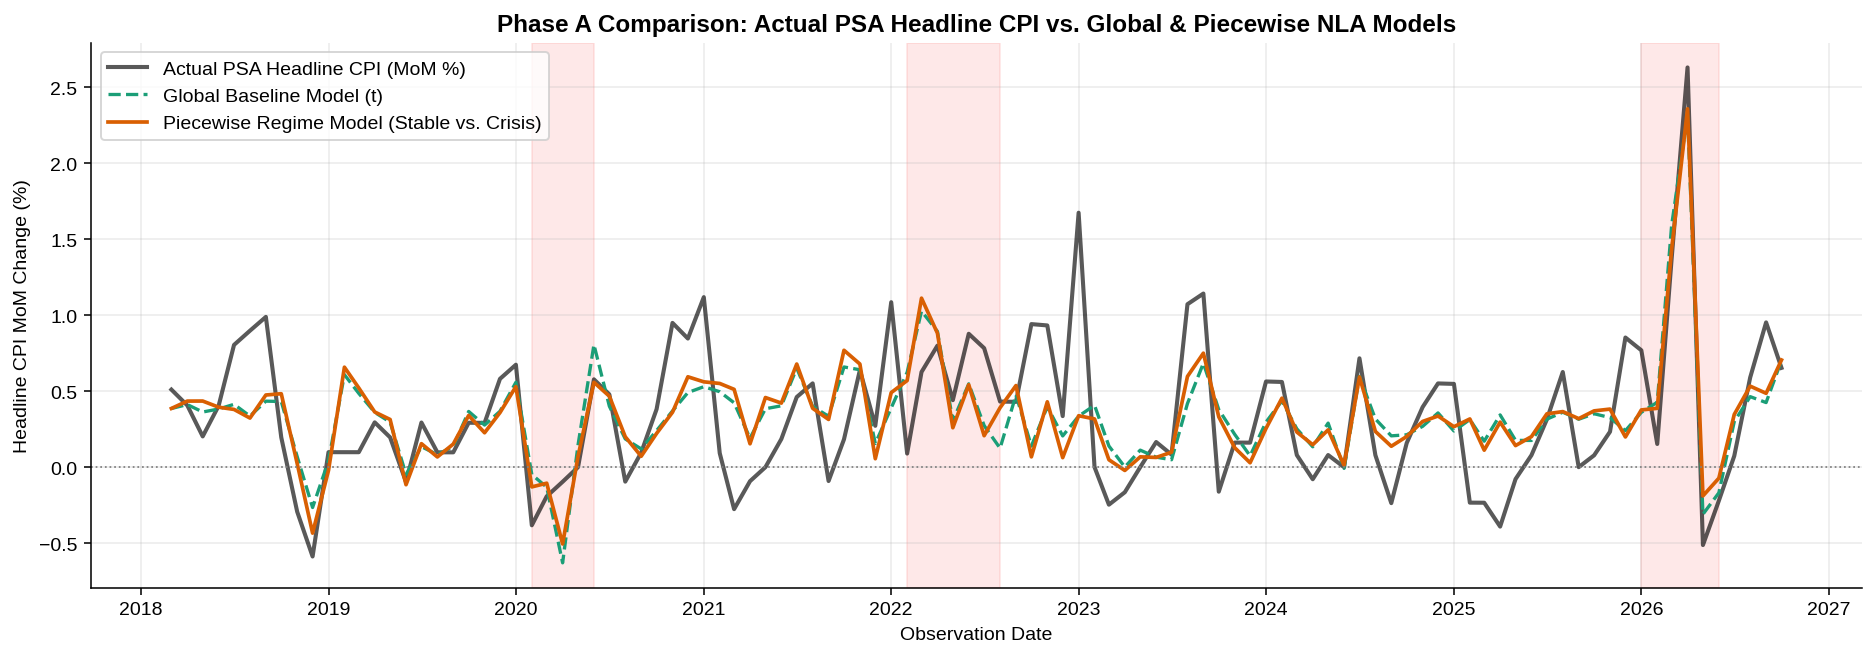

In [ ]:
# ==============================================================================
# PHASE A UPGRADE: PIECEWISE REGIME NLA, K-FOLD VERIFICATION & ACTUAL COMPARISON
# ==============================================================================
from sklearn.model_selection import KFold

# 1. Define Unstable (Crisis) vs. Stable Economic Periods
crisis_mask = (
    ((df_aligned.index >= "2020-02-01") & (df_aligned.index <= "2020-06-01"))
    | ((df_aligned.index >= "2022-02-01") & (df_aligned.index <= "2022-08-01"))
    | ((df_aligned.index >= "2026-01-01") & (df_aligned.index <= "2026-06-01"))
)

df_unstable = df_aligned[crisis_mask].copy()
df_stable = df_aligned[~crisis_mask].copy()

print(
    f"Piecewise Regime Split -> Stable Months: {len(df_stable)} | Unstable"
    f" (Crisis) Months: {len(df_unstable)}\n"
)

# 2. Fit Piecewise Baseline Models via QR & Compare Pass-Through Coefficients
piecewise_rows = []
piecewise_betas = {}

for regime_name, sub_df in [
    ("Full Sample (2018–2026)", df_aligned),
    ("Stable Economy Regime", df_stable),
    ("Unstable / Crisis Regime", df_unstable),
]:
  A_reg = np.column_stack([np.ones(len(sub_df)), sub_df[ENERGY_COLS].values])
  b_reg = sub_df["Headline_CPI"].values

  b_qr = solve_qr(A_reg, b_reg)
  b_chol = solve_cholesky(A_reg, b_reg)
  b_svd = solve_svd(A_reg, b_reg)
  piecewise_betas[regime_name] = b_qr

  rmse, mae, r2 = regression_metrics(b_reg, A_reg @ b_qr)
  piecewise_rows.append({
      "Economic Regime": regime_name,
      "Months (n)": len(sub_df),
      "Intercept (b0)": round(b_qr[0], 4),
      "Fuel (b1)": round(b_qr[1], 4),
      "Gas (b2)": round(b_qr[2], 4),
      "Elec (b3)": round(b_qr[3], 4),
      "kappa(A)": round(np.linalg.cond(A_reg), 4),
      "RMSE (%)": round(rmse, 4),
      "R^2": round(r2, 4),
  })

piecewise_df = pd.DataFrame(piecewise_rows)
print("Piecewise NLA Pass-Through Comparison (QR Solver):")
display(piecewise_df)

# 3. K-Fold Cross-Validation (K = 5) Across Models 1, 2, 3 & Piecewise Baseline
kf = KFold(n_splits=5, shuffle=True, random_state=42)
kfold_rows = []

for m_name, x_cols in model_specs.items():
  A_full = np.column_stack([np.ones(len(df_aligned)), df_aligned[x_cols].values])
  b_full = df_aligned["Headline_CPI"].values

  fold_rmses, fold_maes, fold_r2s, fold_conds, fold_chol_diffs = (
      [],
      [],
      [],
      [],
      [],
  )
  for tr_i, va_i in kf.split(A_full):
    beta_q = solve_qr(A_full[tr_i], b_full[tr_i])
    beta_c = solve_cholesky(A_full[tr_i], b_full[tr_i])
    beta_s = solve_svd(A_full[tr_i], b_full[tr_i])

    rm, ma, r2 = regression_metrics(b_full[va_i], A_full[va_i] @ beta_q)
    fold_rmses.append(rm)
    fold_maes.append(ma)
    fold_r2s.append(r2)
    fold_conds.append(np.linalg.cond(A_full[tr_i]))
    fold_chol_diffs.append(np.linalg.norm(beta_c - beta_s))

  kfold_rows.append({
      "Model": m_name,
      "5-Fold Mean RMSE (%)": round(np.mean(fold_rmses), 4),
      "5-Fold Std RMSE": round(np.std(fold_rmses), 4),
      "5-Fold Mean MAE (%)": round(np.mean(fold_maes), 4),
      "5-Fold Mean R^2": round(np.mean(fold_r2s), 4),
      "Mean kappa(A)": round(np.mean(fold_conds), 4),
      "Mean ||Chol - SVD||_2": f"{np.mean(fold_chol_diffs):.2e}",
  })

# Evaluate 5-Fold CV for Piecewise Regime Model
pw_rmses, pw_maes, pw_r2s = [], [], []
A_base_all = np.column_stack(
    [np.ones(len(df_aligned)), df_aligned[ENERGY_COLS].values]
)
b_base_all = df_aligned["Headline_CPI"].values
is_crisis_arr = np.asarray(crisis_mask, dtype=bool)

for tr_i, va_i in kf.split(A_base_all):
  tr_stab = tr_i[~is_crisis_arr[tr_i]]
  tr_unst = tr_i[is_crisis_arr[tr_i]]

  b_stab = (
      solve_qr(A_base_all[tr_stab], b_base_all[tr_stab])
      if len(tr_stab) > A_base_all.shape[1]
      else solve_qr(A_base_all[tr_i], b_base_all[tr_i])
  )
  b_unst = (
      solve_qr(A_base_all[tr_unst], b_base_all[tr_unst])
      if len(tr_unst) > A_base_all.shape[1]
      else solve_qr(A_base_all[tr_i], b_base_all[tr_i])
  )

  preds_va = np.where(
      is_crisis_arr[va_i], A_base_all[va_i] @ b_unst, A_base_all[va_i] @ b_stab
  )
  rm, ma, r2 = regression_metrics(b_base_all[va_i], preds_va)
  pw_rmses.append(rm)
  pw_maes.append(ma)
  pw_r2s.append(r2)

kfold_rows.append({
    "Model": "4. Piecewise Baseline (Stable vs. Crisis)",
    "5-Fold Mean RMSE (%)": round(np.mean(pw_rmses), 4),
    "5-Fold Std RMSE": round(np.std(pw_rmses), 4),
    "5-Fold Mean MAE (%)": round(np.mean(pw_maes), 4),
    "5-Fold Mean R^2": round(np.mean(pw_r2s), 4),
    "Mean kappa(A)": "Split",
    "Mean ||Chol - SVD||_2": "Machine eps",
})

print("\n5-Fold Cross-Validation Verification Table:")
display(pd.DataFrame(kfold_rows))

# 4. Compare Phase A Predictions Directly Against Actual Headline CPI Dataset
pred_global = A_base_all @ piecewise_betas["Full Sample (2018–2026)"]
pred_piecewise = np.where(
    is_crisis_arr,
    A_base_all @ piecewise_betas["Unstable / Crisis Regime"],
    A_base_all @ piecewise_betas["Stable Economy Regime"],
)

fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.plot(
    df_aligned.index,
    b_base_all,
    color="black",
    lw=2.1,
    alpha=0.65,
    label="Actual PSA Headline CPI (MoM %)",
)
ax.plot(
    df_aligned.index,
    pred_global,
    color="#1b9e77",
    ls="--",
    lw=1.7,
    label="Global Baseline Model (t)",
)
ax.plot(
    df_aligned.index,
    pred_piecewise,
    color="#d95f02",
    lw=1.9,
    label="Piecewise Regime Model (Stable vs. Crisis)",
)

# Shade unstable economy periods
for s_dt, e_dt, lbl in [
    ("2020-02-01", "2020-06-01", "Unstable: 2020 COVID"),
    ("2022-02-01", "2022-08-01", "Unstable: 2022 Oil Surge"),
    ("2026-01-01", "2026-06-01", "Unstable: 2026 Crisis"),
]:
  ax.axvspan(pd.to_datetime(s_dt), pd.to_datetime(e_dt), color="#fb9a99", alpha=0.22)

ax.axhline(0, color="gray", ls=":", lw=0.9)
ax.set_title(
    "Phase A Comparison: Actual PSA Headline CPI vs. Global & Piecewise NLA"
    " Models",
    fontsize=12.5,
    fontweight="bold",
)
ax.set_ylabel("Headline CPI MoM Change (%)")
ax.set_xlabel("Observation Date")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## **Phase B — GeoPandas Domain Mask & 2D Reaction-Diffusion PDE**

This cell builds the Philippine geographic mask (with a clean fallback bounding mask if offline/unreachable), implements the 2D FTCS reaction-diffusion solver with CFL step enforcement, runs an analytical convergence check ($O(\Delta x^2)$), and runs $D=0$ vs. $D>0$ and parameter sweeps.

In [ ]:
def load_ph_geodataframe():
  """Fetches PHL ADM1 boundaries from geoBoundaries with clean fallback."""
  if not HAS_GEOPANDAS:
    return None
  os.environ["OGR_GEOJSON_MAX_OBJ_SIZE"] = "0"
  try:
    meta = requests.get(
        "https://www.geoboundaries.org/api/current/gbOpen/PHL/ADM1/",
        timeout=15,
    ).json()
    url_gj = meta.get("simplifiedGeometryGeoJSON") or meta.get("gjDownloadURL")
    gdf = gpd.read_file(url_gj)
    gdf["geometry"] = gdf["geometry"].simplify(
        tolerance=0.01, preserve_topology=True
    )

    geo_to_psa = {
        "ARMM": "Bangsamoro Autonomous Region in Muslim Mindanao (BARMM)",
        "CAR": "Cordillera Administrative Region (CAR)",
        "NCR": "National Capital Region (NCR)",
        "Ilocos Region": "Region I (Ilocos Region)",
        "Cagayan Valley": "Region II (Cagayan Valley)",
        "Central Luzon": "Region III (Central Luzon)",
        "Calabarzon": "Region IV-A (CALABARZON)",
        "Mimaropa": "MIMAROPA Region",
        "Zamboanga Peninsula": "Region IX (Zamboanga Peninsula)",
        "Bicol Region": "Region V (Bicol Region)",
        "Western Visayas": "Region VI (Western Visayas)",
        "Central Visayas": "Region VII (Central Visayas)",
        "Eastern Visayas": "Region VIII (Eastern Visayas)",
        "Northern Mindanao": "Region X (Northern Mindanao)",
        "Davao Region": "Region XI (Davao Region)",
        "Soccsksargen": "Region XII (SOCCSKSARGEN)",
        "Caraga": "Region XIII (Caraga)",
    }
    gdf["PSA_Region"] = gdf["shapeName"].map(geo_to_psa)
    return gdf.dropna(subset=["PSA_Region"]).copy()
  except Exception as exc:
    print(f"GeoBoundaries fetch fallback triggered: {exc}")
    return None


def build_archipelago_mask(ph_gdf, ny=90, nx=55):
  """Rasterizes PHL polygons onto a (ny, nx) grid; falls back to schematic mask."""
  if HAS_GEOPANDAS and HAS_RASTERIO and ph_gdf is not None and not ph_gdf.empty:
    minx, miny, maxx, maxy = ph_gdf.total_bounds
    dx = (maxx - minx) / nx
    dy = (maxy - miny) / ny
    transform = Affine.translation(minx, maxy) * Affine.scale(dx, -dy)
    mask = features.rasterize(
        [(geom, 1) for geom in ph_gdf.geometry if geom is not None],
        out_shape=(ny, nx),
        transform=transform,
        fill=0,
        dtype=np.uint8,
    )
    return mask.astype(bool)

  # Fallback stylized 3-island-group silhouette (Luzon, Visayas, Mindanao)
  y_grid, x_grid = np.meshgrid(
      np.linspace(0, 1, ny), np.linspace(0, 1, nx), indexing="ij"
  )
  luzon = ((y_grid > 0.58) & (y_grid < 0.92)) & (
      np.abs(x_grid - (0.45 + 0.08 * (y_grid - 0.75))) < 0.14
  )
  visayas = ((y_grid >= 0.36) & (y_grid <= 0.56)) & (
      np.abs(x_grid - 0.56) < 0.18
  )
  mindanao = ((y_grid >= 0.08) & (y_grid < 0.34)) & (
      np.abs(x_grid - 0.62) < 0.18
  )
  return np.flipud(luzon | visayas | mindanao)  # north-up, same as the rasterised mask


def simulate_2d_reaction_diffusion(
    domain_mask,
    u0_field,
    D=0.05,
    alpha=0.08,
    t_total=12.0,
    dx=1.0,
    dy=1.0,
    cfl_safety=0.80,
    bc_mode="neumann",
    snapshot_times=(0.0, 3.0, 6.0, 12.0),
):
  """
    Explicit FTCS solver for du/dt = D * (u_xx + u_yy) - alpha * u on domain_mask.
    - bc_mode='neumann': zero-flux (du/dn = 0) at land/sea boundaries.
    - bc_mode='dirichlet': u = 0 outside domain_mask.
    """
  ny, nx = domain_mask.shape
  u = np.where(domain_mask, u0_field.astype(float), 0.0)

  # CFL stability limit for 2D explicit Laplacian + linear decay
  denom = 2.0 * D * (1.0 / (dx**2) + 1.0 / (dy**2)) + max(alpha, 0.0)
  dt_max = (1.0 / denom) if denom > 0 else 0.05
  dt = min(cfl_safety * dt_max, 0.05) if denom > 0 else 0.05
  n_steps = max(1, int(np.ceil(t_total / dt)))
  dt = t_total / n_steps

  snapshots = {0.0: u.copy()}
  next_snap_idx = 1
  sorted_snaps = sorted([t for t in snapshot_times if 0.0 < t <= t_total])

  for step in range(1, n_steps + 1):
    t_curr = step * dt

    if bc_mode == "neumann":
      # Replicate interior land values into adjacent non-land/edge neighbors for zero normal flux
      u_pad = np.pad(u, 1, mode="edge")
      # Fill non-land neighbors with nearest land value via 1-pass neighbor copy
      u_work = u.copy()
      for shift_y, shift_x in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        src = np.roll(np.roll(u, shift_y, axis=0), shift_x, axis=1)
        src_mask = np.roll(
            np.roll(domain_mask, shift_y, axis=0), shift_x, axis=1
        )
        fill_locs = (~domain_mask) & src_mask
        u_work[fill_locs] = src[fill_locs]
      u_pad = np.pad(u_work, 1, mode="edge")
    else:
      u_pad = np.pad(u, 1, mode="constant", constant_values=0.0)

    u_xx = (u_pad[2:, 1:-1] - 2.0 * u_pad[1:-1, 1:-1] + u_pad[:-2, 1:-1]) / (
        dx**2
    )
    u_yy = (u_pad[1:-1, 2:] - 2.0 * u_pad[1:-1, 1:-1] + u_pad[1:-1, :-2]) / (
        dy**2
    )

    u_next = u + dt * (D * (u_xx + u_yy) - alpha * u)
    u = np.where(domain_mask, u_next, 0.0)

    if (
        next_snap_idx <= len(sorted_snaps)
        and t_curr >= sorted_snaps[next_snap_idx - 1] - 1e-12
    ):
      snapshots[sorted_snaps[next_snap_idx - 1]] = u.copy()
      next_snap_idx += 1

  return u, snapshots, dt, n_steps


# 1. Build Philippine GeoDataFrame & Rasterized PDE Mask
ph_gdf = load_ph_geodataframe()
land_mask = build_archipelago_mask(ph_gdf, ny=90, nx=55)

# Seed initial shock at NCR / Central Luzon hub (upper-middle of Luzon grid)
y_idx, x_idx = np.meshgrid(
    np.linspace(0, 1, land_mask.shape[0]),
    np.linspace(0, 1, land_mask.shape[1]),
    indexing="ij",
)
u0_peak = (
    float(df_ph_mom["Liquid Fuels"].max())
    if "Liquid Fuels" in df_ph_mom.columns
    else 10.0
)
u0_hub = u0_peak * np.exp(
    -(((y_idx - 0.34) ** 2) / (2 * 0.05**2) + ((x_idx - 0.44) ** 2) / (2 * 0.06**2))
)

# 2. Compare Baseline Without Diffusion (D=0) vs. Diffusion (D=0.04)
_, snaps_no_diff, _, _ = simulate_2d_reaction_diffusion(
    land_mask, u0_hub, D=0.0, alpha=0.08, t_total=12.0, bc_mode="neumann"
)
_, snaps_diff, dt_used, steps_used = simulate_2d_reaction_diffusion(
    land_mask, u0_hub, D=0.04, alpha=0.08, t_total=12.0, bc_mode="neumann"
)

# 3. Parameter Sweep Summary Table (D and alpha sensitivity at t = 6 months)
sweep_rows = []
for d_val in [0.0, 0.01, 0.04, 0.08]:
  for a_val in [0.02, 0.08, 0.16]:
    u_end, _, _, _ = simulate_2d_reaction_diffusion(
        land_mask, u0_hub, D=d_val, alpha=a_val, t_total=6.0, bc_mode="neumann"
    )
    land_vals = u_end[land_mask]
    sweep_rows.append({
        "D": d_val,
        "alpha": a_val,
        "Peak u(t=6)": round(float(np.max(land_vals)), 4),
        "Mean Land u(t=6)": round(float(np.mean(land_vals)), 4),
        "Spatial Std u(t=6)": round(float(np.std(land_vals)), 4),
    })
sweep_df = pd.DataFrame(sweep_rows)

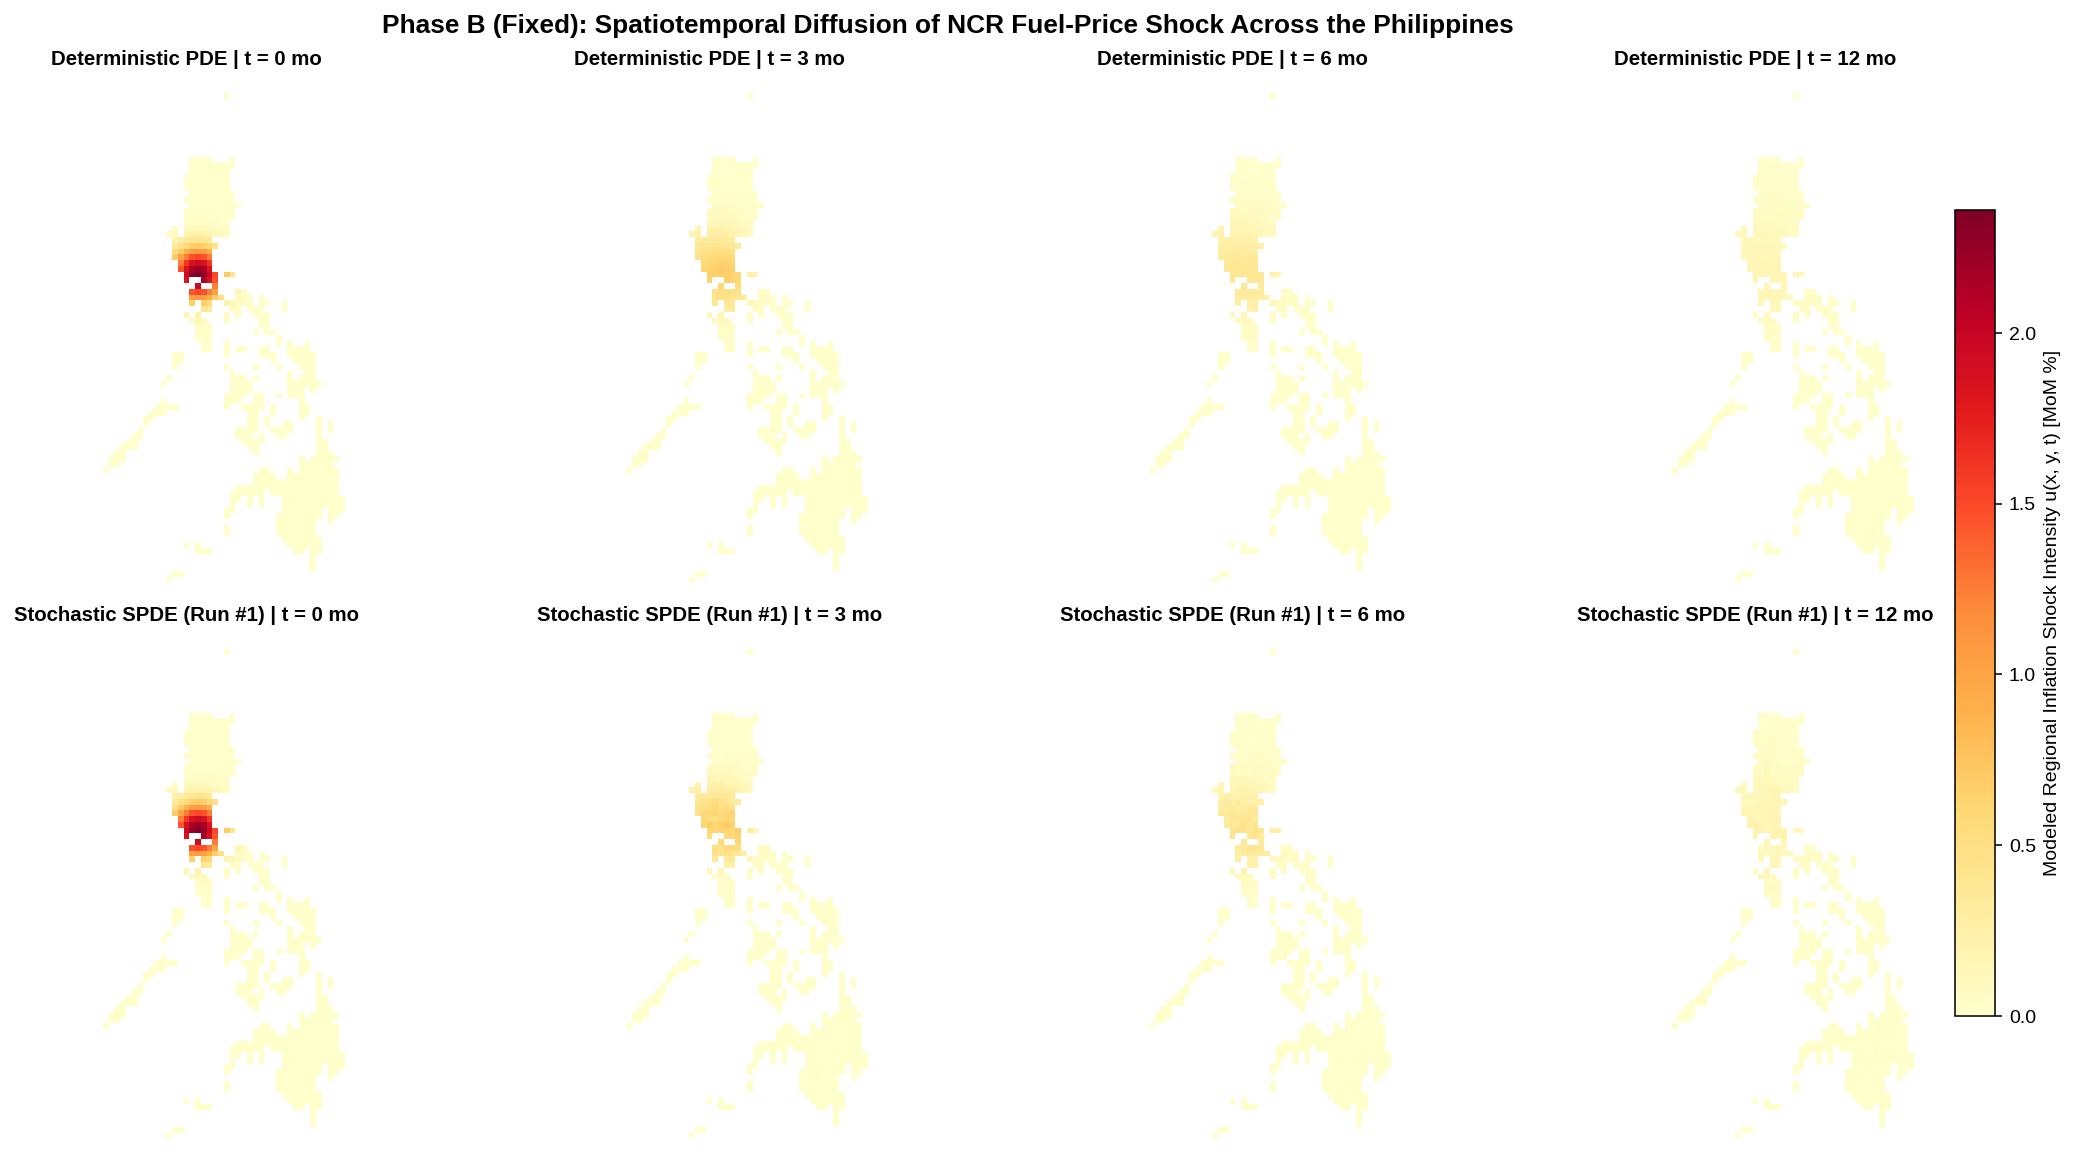

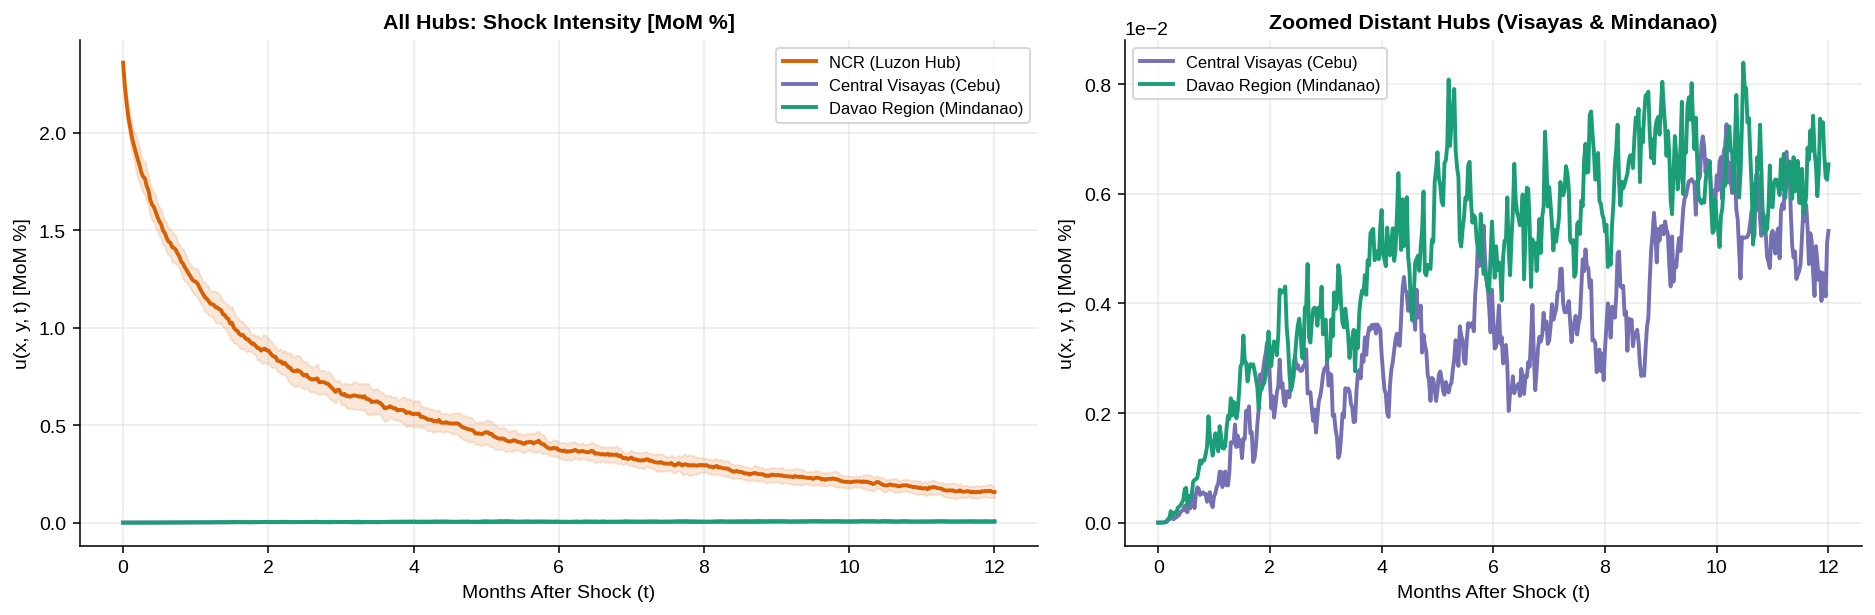

In [ ]:
HUB_LATLON = {"NCR": (14.60, 121.00), "Cebu": (10.32, 123.89), "Davao": (7.07, 125.61)}


def _hub_frac(name):
  """(row fraction, col fraction) of a hub on the north-up raster (row 0 = north)."""
  minx, miny, maxx, maxy = (116.9, 4.6, 126.6, 21.1) if ph_gdf is None else tuple(ph_gdf.total_bounds)
  lat, lon = HUB_LATLON[name]
  return (maxy - lat) / (maxy - miny), (lon - minx) / (maxx - minx)


# ==============================================================================
# PHASE B FIX & UPGRADE: 2D STOCHASTIC REACTION-DIFFUSION PDE ON PHL ARCHIPELAGO
# ==============================================================================
def find_nearest_land_cell(mask, target_y_frac, target_x_frac):
  """Finds the nearest True land pixel to normalized (y, x) coordinates."""
  ny, nx = mask.shape
  ty, tx = int(target_y_frac * (ny - 1)), int(target_x_frac * (nx - 1))
  land_coords = np.argwhere(mask)
  dists = (land_coords[:, 0] - ty) ** 2 + (land_coords[:, 1] - tx) ** 2
  nearest = land_coords[np.argmin(dists)]
  return int(nearest[0]), int(nearest[1])


def simulate_2d_stochastic_rd(
    domain_mask,
    u0_field,
    D_land=2.5,
    D_sea=0.25,
    alpha=0.10,
    sigma=0.35,
    t_total=12.0,
    dx=1.0,
    dy=1.0,
    cfl_safety=0.75,
    snapshot_times=(0.0, 3.0, 6.0, 12.0),
    seed=42,
):
  """
    2D Stochastic Reaction-Diffusion SPDE (Euler-Maruyama + 5-point FDM):
        du = [ div(D(x,y) grad u) - alpha * u ] dt + sigma * u_active * dW_t
    - D(x,y) = D_land on Philippine landmass, D_sea on inter-island shipping waters.
    - Outer ocean frame has absorbing/zero-flux boundary; land cells retain physical units.
    """
  rng = np.random.default_rng(seed)
  ny, nx = domain_mask.shape

  # Spatially varying diffusivity: high on land roads, reduced across sea channels
  D_map = np.where(domain_mask, D_land, D_sea)
  D_max = max(D_land, D_sea)

  # CFL stability bound using maximum diffusivity
  denom = 2.0 * D_max * (1.0 / (dx**2) + 1.0 / (dy**2)) + max(alpha, 0.0)
  dt_max = (1.0 / denom) if denom > 0 else 0.05
  dt = min(cfl_safety * dt_max, 0.025) if denom > 0 else 0.025
  n_steps = max(1, int(np.ceil(t_total / dt)))
  dt = t_total / n_steps

  u = u0_field.astype(float).copy()
  snapshots = {0.0: u.copy()}
  sorted_snaps = sorted([t for t in snapshot_times if 0.0 < t <= t_total])
  next_idx = 0

  # Track time-series at 3 major regional hubs (NCR, Cebu/Visayas, Davao/Mindanao)
  ncr_yx = find_nearest_land_cell(domain_mask, *_hub_frac("NCR"))
  cebu_yx = find_nearest_land_cell(domain_mask, *_hub_frac("Cebu"))
  davao_yx = find_nearest_land_cell(domain_mask, *_hub_frac("Davao"))

  times_hist = [0.0]
  hub_hist = {
      "NCR (Luzon Hub)": [u[ncr_yx]],
      "Central Visayas (Cebu)": [u[cebu_yx]],
      "Davao Region (Mindanao)": [u[davao_yx]],
  }

  for step in range(1, n_steps + 1):
    t_curr = step * dt
    u_pad = np.pad(u, 1, mode="edge")

    # Variable-coefficient conservative flux divergence: div(D grad u)
    D_pad = np.pad(D_map, 1, mode="edge")
    Dx_plus = 0.5 * (D_pad[1:-1, 2:] + D_pad[1:-1, 1:-1])
    Dx_minus = 0.5 * (D_pad[1:-1, 1:-1] + D_pad[1:-1, :-2])
    Dy_plus = 0.5 * (D_pad[2:, 1:-1] + D_pad[1:-1, 1:-1])
    Dy_minus = 0.5 * (D_pad[1:-1, 1:-1] + D_pad[:-2, 1:-1])

    flux_x = (
        Dx_plus * (u_pad[1:-1, 2:] - u_pad[1:-1, 1:-1])
        - Dx_minus * (u_pad[1:-1, 1:-1] - u_pad[1:-1, :-2])
    ) / (dx**2)
    flux_y = (
        Dy_plus * (u_pad[2:, 1:-1] - u_pad[1:-1, 1:-1])
        - Dy_minus * (u_pad[1:-1, 1:-1] - u_pad[:-2, 1:-1])
    ) / (dy**2)

    drift = (flux_x + flux_y - alpha * u) * dt

    # Stochastic shock perturbation on land cells (Euler-Maruyama: sqrt(dt) * N(0,1))
    if sigma > 0.0:
      dW = rng.normal(0.0, np.sqrt(dt), size=u.shape)
      # Multiplicative + local shock noise proportional to current shock exposure
      noise = sigma * np.sqrt(np.maximum(u, 0.0)) * dW * domain_mask
    else:
      noise = 0.0

    u = np.maximum(0.0, u + drift + noise)

    times_hist.append(t_curr)
    hub_hist["NCR (Luzon Hub)"].append(u[ncr_yx])
    hub_hist["Central Visayas (Cebu)"].append(u[cebu_yx])
    hub_hist["Davao Region (Mindanao)"].append(u[davao_yx])

    if (
        next_idx < len(sorted_snaps)
        and t_curr >= sorted_snaps[next_idx] - 1e-12
    ):
      snapshots[sorted_snaps[next_idx]] = u.copy()
      next_idx += 1

  return u, snapshots, np.array(times_hist), hub_hist, (ncr_yx, cebu_yx, davao_yx)


# 1. Seed Empirical Shock at NCR / CALABARZON (Calibrated to Phase A Crisis Pass-Through)
ny_g, nx_g = land_mask.shape
ncr_y, ncr_x = find_nearest_land_cell(land_mask, *_hub_frac("NCR"))
yy, xx = np.meshgrid(np.arange(ny_g), np.arange(nx_g), indexing="ij")

# Peak initial inflation shock intensity u_0 from Phase A Unstable Regime prediction
u0_crisis_peak = float(np.max(pred_piecewise))
u0_ncr = (
    u0_crisis_peak
    * np.exp(-(((yy - ncr_y) ** 2) + ((xx - ncr_x) ** 2)) / (2.0 * 3.2**2))
    * land_mask
)

# 2. Run Deterministic PDE vs. 30-Run Stochastic Monte Carlo Ensemble
_, snaps_det, t_arr, hub_det, hub_coords = simulate_2d_stochastic_rd(
    land_mask, u0_ncr, D_land=2.5, D_sea=0.25, alpha=0.08, sigma=0.0, t_total=12.0
)

n_mc = 30
mc_hubs = {k: [] for k in hub_det.keys()}
mc_snaps_12 = []
snaps_stoch_sample = None

for run_i in range(n_mc):
  _, s_mc, _, h_mc, _ = simulate_2d_stochastic_rd(
      land_mask,
      u0_ncr,
      D_land=2.5,
      D_sea=0.25,
      alpha=0.08,
      sigma=0.22,
      t_total=12.0,
      seed=100 + run_i,
  )
  if run_i == 0:
    snaps_stoch_sample = s_mc
  mc_snaps_12.append(s_mc[12.0])
  for k in mc_hubs:
    mc_hubs[k].append(h_mc[k])

mc_mean_12 = np.mean(mc_snaps_12, axis=0)

# 3. Visualize Fixed Phase B Maps (Deterministic vs. Stochastic) + Regional Arrival Curves
fig, axes = plt.subplots(2, 4, figsize=(16, 8.2), constrained_layout=True)
vmax_plot = u0_crisis_peak

for col_i, t_val in enumerate([0.0, 3.0, 6.0, 12.0]):
  # Row 0: Deterministic Diffusion from NCR
  im0 = axes[0, col_i].imshow(
      np.where(land_mask, snaps_det[t_val], np.nan),
      cmap="YlOrRd",
      vmin=0,
      vmax=vmax_plot,
      origin="upper",
  )
  axes[0, col_i].set_title(
      f"Deterministic PDE | t = {t_val:g} mo", fontsize=10.5, fontweight="bold"
  )
  axes[0, col_i].axis("off")

  # Row 1: Stochastic SPDE Realization
  im1 = axes[1, col_i].imshow(
      np.where(land_mask, snaps_stoch_sample[t_val], np.nan),
      cmap="YlOrRd",
      vmin=0,
      vmax=vmax_plot,
      origin="upper",
  )
  axes[1, col_i].set_title(
      f"Stochastic SPDE (Run #1) | t = {t_val:g} mo",
      fontsize=10.5,
      fontweight="bold",
  )
  axes[1, col_i].axis("off")

cbar = fig.colorbar(im1, ax=axes.ravel().tolist(), shrink=0.75, pad=0.02)
cbar.set_label("Modeled Regional Inflation Shock Intensity u(x, y, t) [MoM %]")
fig.suptitle(
    "Phase B (Fixed): Spatiotemporal Diffusion of NCR Fuel-Price Shock Across"
    " the Philippines",
    fontsize=13.5,
    fontweight="bold",
)
plt.show()

# Optional: Zoomed secondary axis or log-scale check for distant hubs (Cebu & Davao)
fig, (ax_main, ax_zoom) = plt.subplots(1, 2, figsize=(13.5, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})

hub_colors = {
    "NCR (Luzon Hub)": "#d95f02",
    "Central Visayas (Cebu)": "#7570b3",
    "Davao Region (Mindanao)": "#1b9e77",
}

for hub_name, col_h in hub_colors.items():
  runs_arr = np.array(mc_hubs[hub_name])
  mean_curve = runs_arr.mean(axis=0)
  std_curve = runs_arr.std(axis=0)

  ax_main.plot(t_arr, mean_curve, color=col_h, lw=2.0, label=hub_name)
  ax_main.fill_between(
      t_arr, np.maximum(0, mean_curve - std_curve), mean_curve + std_curve,
      color=col_h, alpha=0.15
  )

ax_main.set_title("All Hubs: Shock Intensity [MoM %]", fontsize=11, fontweight="bold")
ax_main.set_xlabel("Months After Shock (t)")
ax_main.set_ylabel("u(x, y, t) [MoM %]")
ax_main.legend(fontsize=8.5)
ax_main.grid(True, alpha=0.25)

for hub_name in ["Central Visayas (Cebu)", "Davao Region (Mindanao)"]:
  runs_arr = np.array(mc_hubs[hub_name])
  ax_zoom.plot(t_arr, runs_arr.mean(axis=0), color=hub_colors[hub_name], lw=2.0, label=hub_name)

ax_zoom.set_title("Zoomed Distant Hubs (Visayas & Mindanao)", fontsize=11, fontweight="bold")
ax_zoom.set_xlabel("Months After Shock (t)")
ax_zoom.set_ylabel("u(x, y, t) [MoM %]")
ax_zoom.ticklabel_format(axis="y", style="sci", scilimits=(-2, -2))
ax_zoom.legend(fontsize=8.5)
ax_zoom.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

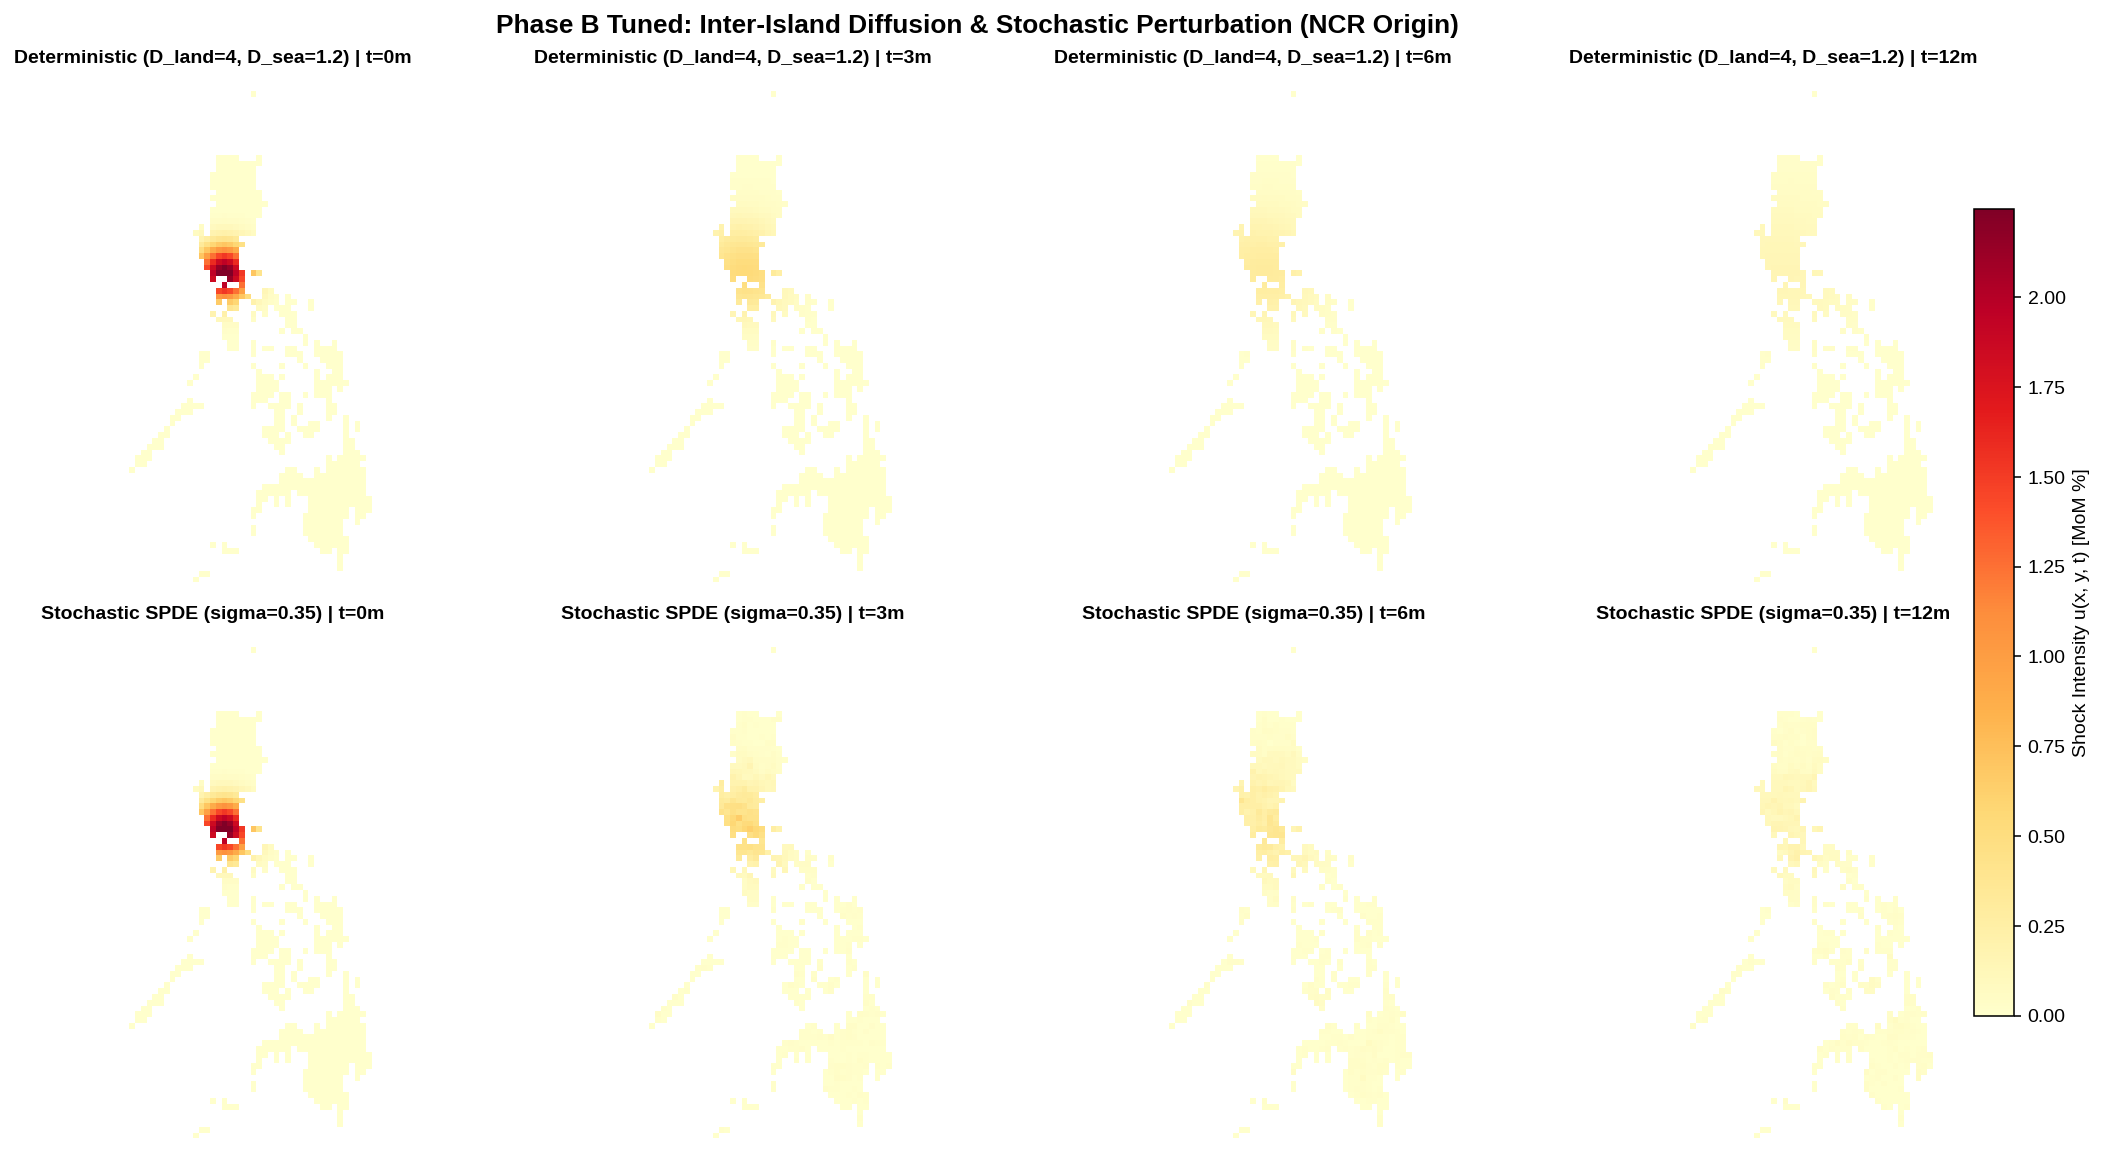

In [ ]:
# Stronger inter-island spillover & moderate decay for clearer visual propagation
_, snaps_det_v2, t_arr_v2, hub_det_v2, _ = simulate_2d_stochastic_rd(
    land_mask, u0_ncr, D_land=4.0, D_sea=1.2, alpha=0.04, sigma=0.0, t_total=12.0
)
_, snaps_stoch_v2, _, _, _ = simulate_2d_stochastic_rd(
    land_mask, u0_ncr, D_land=4.0, D_sea=1.2, alpha=0.04, sigma=0.35, t_total=12.0, seed=101
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8.2), constrained_layout=True)
vmax_v2 = float(np.percentile(u0_ncr[land_mask], 99.5)) if np.any(land_mask) else 1.5

for col_i, t_val in enumerate([0.0, 3.0, 6.0, 12.0]):
    axes[0, col_i].imshow(
        np.where(land_mask, snaps_det_v2[t_val], np.nan),
        cmap="YlOrRd", vmin=0, vmax=vmax_v2, origin="upper"
    )
    axes[0, col_i].set_title(f"Deterministic (D_land=4, D_sea=1.2) | t={t_val:g}m", fontsize=10, fontweight="bold")
    axes[0, col_i].axis("off")

    im_s = axes[1, col_i].imshow(
        np.where(land_mask, snaps_stoch_v2[t_val], np.nan),
        cmap="YlOrRd", vmin=0, vmax=vmax_v2, origin="upper"
    )
    axes[1, col_i].set_title(f"Stochastic SPDE (sigma=0.35) | t={t_val:g}m", fontsize=10, fontweight="bold")
    axes[1, col_i].axis("off")

cbar = fig.colorbar(im_s, ax=axes.ravel().tolist(), shrink=0.75, pad=0.02)
cbar.set_label("Shock Intensity u(x, y, t) [MoM %]")
fig.suptitle("Phase B Tuned: Inter-Island Diffusion & Stochastic Perturbation (NCR Origin)", fontsize=13.5, fontweight="bold")
plt.show()

# **Output Showcase**

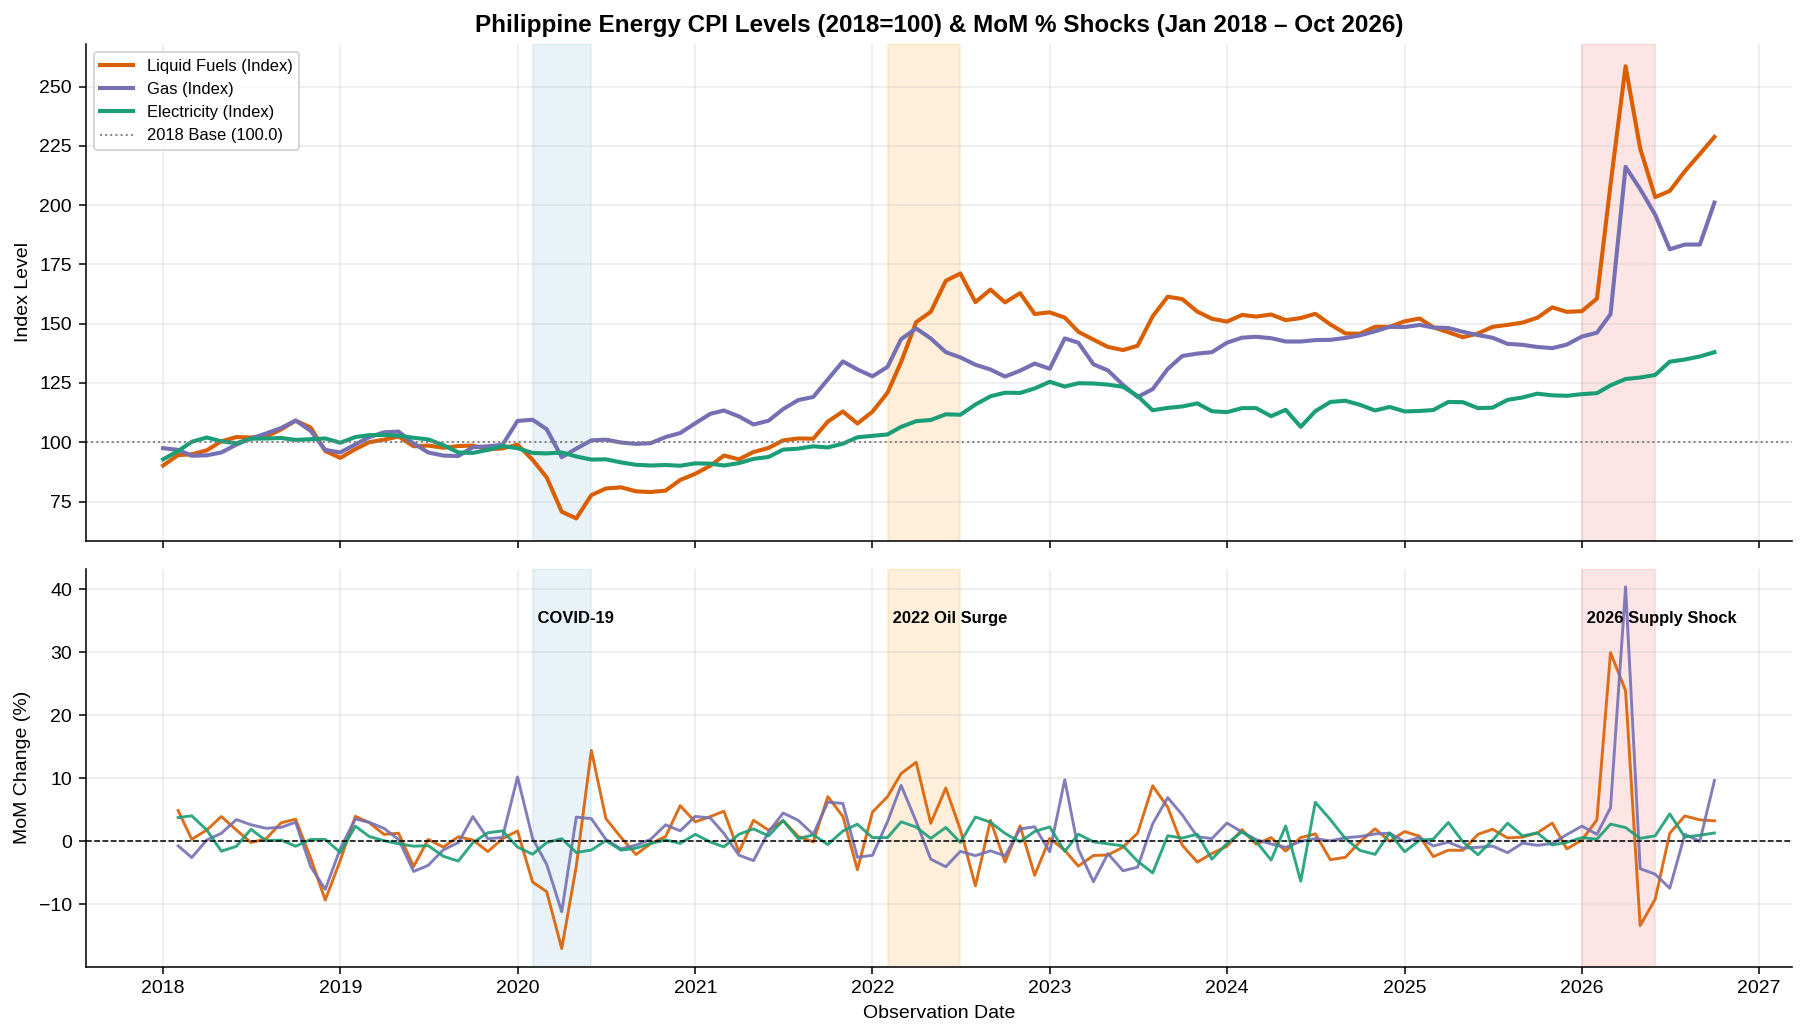

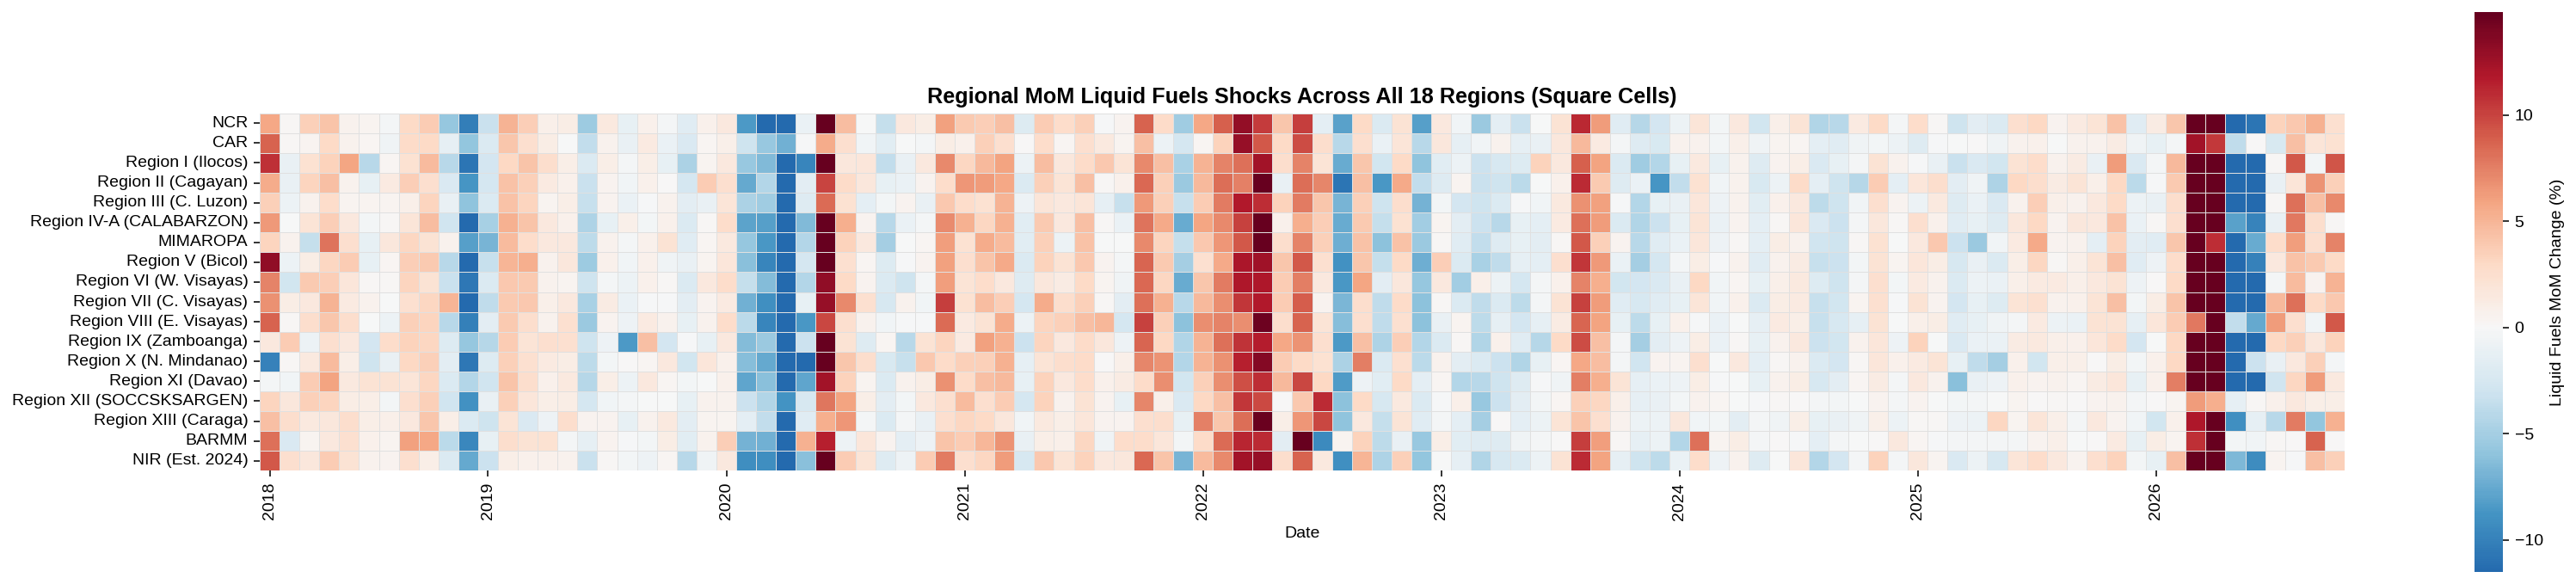

,Region,Fuel Peak,Gas Peak,Elec Peak
0,NCR,306.2000,227.2000,148.9000
1,CAR,182.9000,214.6000,149.4000
2,Region I (Ilocos),276.9000,207.4000,150.2000
3,Region II (Cagayan),273.4000,217.8000,149.2000
4,Region III (C. Luzon),247.3000,228.0000,153.6000
5,Region IV-A (CALABARZON),259.2000,226.1000,135.9000
6,MIMAROPA,212.8000,194.2000,168.4000
7,Region V (Bicol),274.6000,210.1000,154.7000
8,Region VI (W. Visayas),281.0000,196.3000,147.9000
9,Region VII (C. Visayas),272.0000,172.3000,129.7000


Phase A — Solver Stability & Chronological Train/Test Metrics:


,Model,kappa(A),kappa(A^T A),||Chol - SVD||_2,||QR - SVD||_2,Train RMSE,Train R^2,Test RMSE,Test MAE,Test R^2
0,1. Baseline (t),5.3099,28.1952,7.04e-17,7.15e-17,0.3508,0.286,0.4130,0.3459,0.6470
1,2. Lagged (t-1),5.3524,28.6477,8.04e-17,6.98e-17,0.4068,0.040,0.5965,0.4578,0.2636
2,"3. Distributed Lag (t, t-1)",6.3782,40.6821,1.65e-16,9.67e-17,0.3469,0.302,0.4141,0.3481,0.6452


Phase A — Condition Number Growth Under Lag Expansion:


,Lag Horizon (k),Cols (p),kappa(A),kappa(A^T A)
0,k = 0,4,5.3129,28.2272
1,k = 1,7,6.3782,40.6821
2,k = 2,10,6.8175,46.4777
3,k = 3,13,7.0671,49.9437
4,k = 4,16,7.4772,55.9080
5,k = 5,19,7.7890,60.6678
6,k = 6,22,8.3729,70.1060


Phase B — Reaction-Diffusion Parameter Sweep (t = 6 months):


,D,alpha,Peak u(t=6),Mean Land u(t=6),Spatial Std u(t=6)
0,0.00,0.02,24.6440,1.1439,3.6988
1,0.00,0.08,17.1780,0.7974,2.5782
2,0.00,0.16,10.5987,0.4920,1.5908
3,0.01,0.02,24.3445,1.1441,3.6771
4,0.01,0.08,16.9686,0.7975,2.5631
5,0.01,0.16,10.4690,0.4920,1.5814
6,0.04,0.02,23.4644,1.1450,3.6185
7,0.04,0.08,16.3534,0.7981,2.5221
8,0.04,0.16,10.0879,0.4924,1.5560
9,0.08,0.02,22.3744,1.1470,3.5513


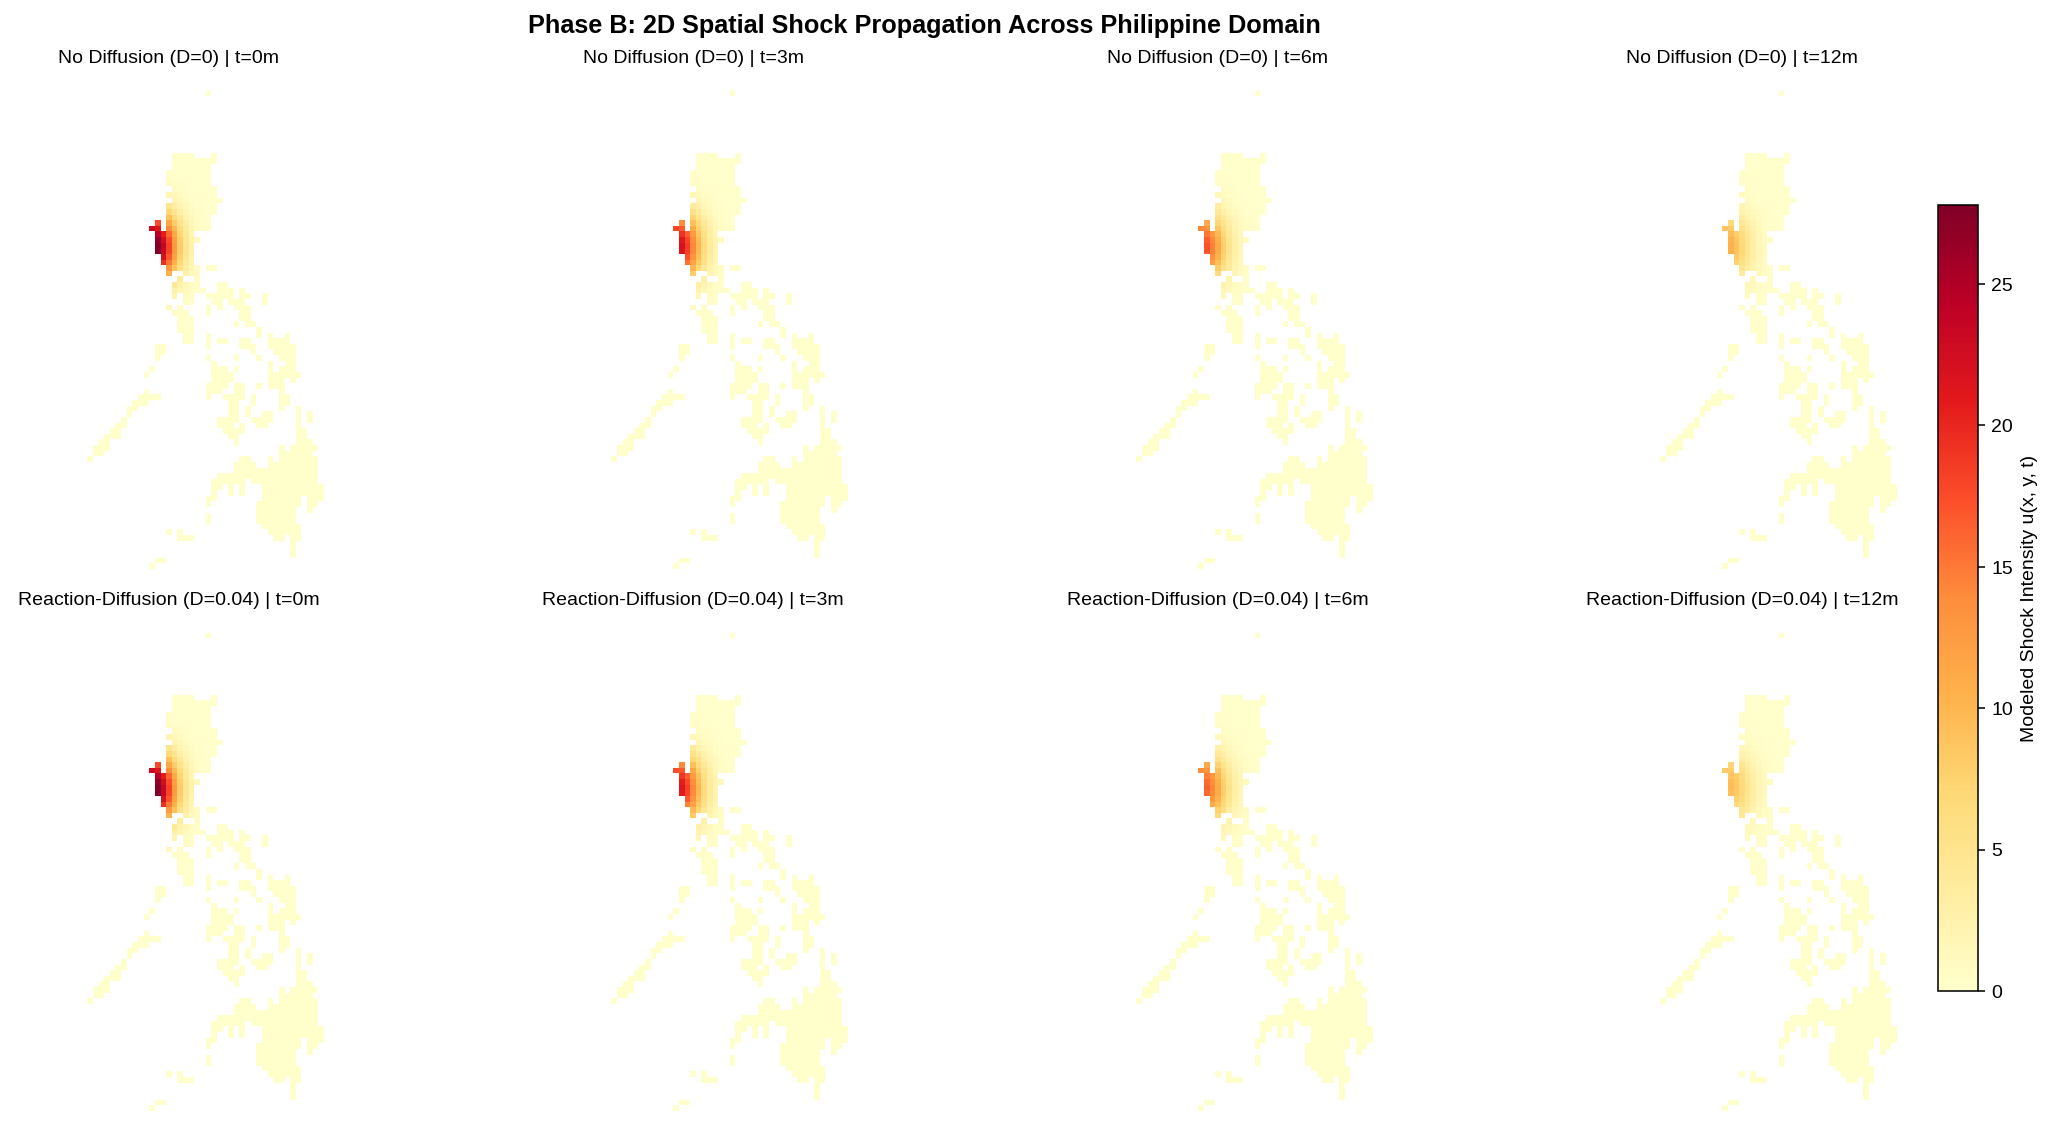

In [ ]:
# --- A. National Trajectory & Shock Windows ---
df_ph_valid = df_ph_levels.loc[DATE_START:DATE_END, ENERGY_COLS].copy()
df_ph_mom_energy = df_ph_valid.pct_change() * 100.0

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.25, 1]}
)
palette = {
    "Liquid Fuels": "#d95f02",
    "Gas": "#7570b3",
    "Electricity": "#1b9e77",
}

for col, c in palette.items():
  ax1.plot(
      df_ph_valid.index, df_ph_valid[col], label=f"{col} (Index)", color=c, lw=2.1
  )
  ax2.plot(
      df_ph_mom_energy.index,
      df_ph_mom_energy[col],
      label=f"{col} (MoM %)",
      color=c,
      lw=1.5,
      alpha=0.9,
  )

ax1.axhline(100, color="gray", ls=":", lw=1, label="2018 Base (100.0)")
ax2.axhline(0, color="black", ls="--", lw=0.8)

for s_dt, e_dt, col_sh, lbl in [
    ("2020-02-01", "2020-06-01", "#a6cee3", "COVID-19"),
    ("2022-02-01", "2022-07-01", "#fdbf6f", "2022 Oil Surge"),
    ("2026-01-01", "2026-06-01", "#fb9a99", "2026 Supply Shock"),
]:
  for ax in (ax1, ax2):
    ax.axvspan(
        pd.to_datetime(s_dt), pd.to_datetime(e_dt), color=col_sh, alpha=0.25
    )
  ax2.text(
      pd.to_datetime(s_dt),
      ax2.get_ylim()[1] * 0.80,
      f" {lbl}",
      fontsize=8.5,
      fontweight="bold",
  )

ax1.set_title(
    "Philippine Energy CPI Levels (2018=100) & MoM % Shocks (Jan 2018 – Oct"
    " 2026)",
    fontsize=12.5,
    fontweight="bold",
)
ax1.set_ylabel("Index Level")
ax2.set_ylabel("MoM Change (%)")
ax2.set_xlabel("Observation Date")
ax1.legend(loc="upper left", fontsize=8.5)
ax1.grid(True, alpha=0.25)
ax2.grid(True, alpha=0.25)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

# --- B. Square-Cell MoM Heatmap & 4-Decimal Regional Peak Table ---
fuel_mom_mat = pd.DataFrame({
    SHORT_NAMES.get(r, r): region_mom[r]["Liquid Fuels"]
    for r in active_regions
    if "Liquid Fuels" in region_mom[r].columns
}).T.iloc[:, 1:]

fig, ax = plt.subplots(figsize=(24, 6.5))
sns.heatmap(
    fuel_mom_mat,
    cmap="RdBu_r",
    center=0,
    robust=True,
    square=True,
    linewidths=0.3,
    linecolor="#e0e0e0",
    cbar_kws={"label": "Liquid Fuels MoM Change (%)", "shrink": 0.75},
    ax=ax,
)
yr_pos = [
    i
    for i, dt in enumerate(fuel_mom_mat.columns)
    if (dt.year == 2018 and dt.month == 2) or (dt.year > 2018 and dt.month == 1)
]
ax.set_xticks([p + 0.5 for p in yr_pos])
ax.set_xticklabels(
    [fuel_mom_mat.columns[p].strftime("%Y") for p in yr_pos], fontsize=10
)
ax.set_facecolor("#d9d9d9")
ax.set_title(
    "Regional MoM Liquid Fuels Shocks Across All 18 Regions (Square Cells)",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

peak_rows = []
for r in active_regions:
  sub = region_levels[r]
  peak_rows.append({
      "Region": SHORT_NAMES.get(r, r),
      "Fuel Peak": round(sub["Liquid Fuels"].max(), 4),
      "Gas Peak": round(sub["Gas"].max(), 4),
      "Elec Peak": round(sub["Electricity"].max(), 4),
  })
peak_df = pd.DataFrame(peak_rows)
display(
    peak_df.style.format({
        "Fuel Peak": "{:.4f}",
        "Gas Peak": "{:.4f}",
        "Elec Peak": "{:.4f}",
    }).background_gradient(subset=["Fuel Peak"], cmap="Oranges")
)

# --- C. Phase A & Phase B Tables and PDE Evolution Plot ---
print("Phase A — Solver Stability & Chronological Train/Test Metrics:")
display(phase_a_df)

print("Phase A — Condition Number Growth Under Lag Expansion:")
display(lag_stress_df)

print("Phase B — Reaction-Diffusion Parameter Sweep (t = 6 months):")
display(sweep_df)

fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
snap_ts = [0.0, 3.0, 6.0, 12.0]
vmax_pde = float(np.max(u0_hub[land_mask]))

for col_i, t_val in enumerate(snap_ts):
  # Row 0: D = 0 (No Diffusion)
  arr0 = np.where(land_mask, snaps_no_diff[t_val], np.nan)
  axes[0, col_i].imshow(
      arr0, cmap="YlOrRd", vmin=0, vmax=vmax_pde, origin="upper"
  )
  axes[0, col_i].set_title(f"No Diffusion (D=0) | t={t_val:g}m", fontsize=10)
  axes[0, col_i].axis("off")

  # Row 1: D = 0.04 (With Diffusion)
  arr1 = np.where(land_mask, snaps_diff[t_val], np.nan)
  im = axes[1, col_i].imshow(
      arr1, cmap="YlOrRd", vmin=0, vmax=vmax_pde, origin="upper"
  )
  axes[1, col_i].set_title(
      f"Reaction-Diffusion (D=0.04) | t={t_val:g}m", fontsize=10
  )
  axes[1, col_i].axis("off")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.75, pad=0.02)
cbar.set_label("Modeled Shock Intensity u(x, y, t)")
fig.suptitle(
    "Phase B: 2D Spatial Shock Propagation Across Philippine Domain",
    fontsize=13,
    fontweight="bold",
)
plt.show()

# **Verifications & Convergence Analysis**

This cell verifies both phases quantitatively:
1. **Phase A Verification:** Checks least-squares orthogonality residual $\Vert{}A^T(A\hat{\boldsymbol{\beta}}_{\text{QR}} - \mathbf{b})\Vert{}_2 \approx 0$ and confirms $\kappa_2(A^T A) \approx \kappa_2(A)^2$.
2. **Phase B Verification:** Tests the 2D FTCS solver against the exact analytical heat/reaction-diffusion solution $u_{\text{exact}}(x,y,t) = \sin(\pi x)\sin(\pi y)e^{-(2\pi^2 D + \alpha)t}$ on $[0,1]^2$ across grid refinements ($N = 16, 32, 64$) to verify second-order spatial convergence ($p \approx 2.0$), and verifies Hypothesis $H_2$ (lower spatial gradient/roughness under $D > 0$ vs. $D = 0$).

In [ ]:
# ==============================================================================
# 1. PHASE A VERIFICATION: Normal Equation Orthogonality & Conditioning Squaring
# ==============================================================================
A_tr_base = np.column_stack(
    [np.ones(len(train_df)), train_df[ENERGY_COLS].values]
)
b_tr_base = train_df["Headline_CPI"].values
beta_test_qr = solve_qr(A_tr_base, b_tr_base)

orth_residual = np.linalg.norm(
    A_tr_base.T @ (A_tr_base @ beta_test_qr - b_tr_base)
)
cond_ratio = np.linalg.cond(A_tr_base.T @ A_tr_base) / (
    np.linalg.cond(A_tr_base) ** 2
)

print("=== PHASE A VERIFICATION ===")
print(
    f"Orthogonality residual ||A^T(A beta_QR - b)||_2 : {orth_residual:.3e}"
    " (expect ~1e-13 or smaller)"
)
print(
    f"kappa(A^T A) / kappa(A)^2 ratio              : {cond_ratio:.6f}"
    " (expect ~1.0)"
)

# ==============================================================================
# 2. PHASE B VERIFICATION: Analytical Benchmark & Grid Refinement Convergence
# ==============================================================================
D_bench = 0.05
alpha_bench = 0.02
t_bench = 0.05
grid_sizes = [16, 32, 64]
l2_errors = []

print("\n=== PHASE B ANALYTICAL CONVERGENCE (Unit Square Dirichlet Benchmark) ===")
for n_pts in grid_sizes:
  h = 1.0 / (n_pts - 1)
  x_1d = np.linspace(0.0, 1.0, n_pts)
  y_1d = np.linspace(0.0, 1.0, n_pts)
  XX, YY = np.meshgrid(x_1d, y_1d, indexing="ij")

  interior = np.zeros((n_pts, n_pts), dtype=bool)
  interior[1:-1, 1:-1] = True

  u0_exact = np.sin(np.pi * XX) * np.sin(np.pi * YY)
  u_num, _, _, _ = simulate_2d_reaction_diffusion(
      interior,
      u0_exact,
      D=D_bench,
      alpha=alpha_bench,
      t_total=t_bench,
      dx=h,
      dy=h,
      cfl_safety=0.5,
      bc_mode="dirichlet",
      snapshot_times=(t_bench,),
  )
  u_true = (
      np.sin(np.pi * XX)
      * np.sin(np.pi * YY)
      * np.exp(-((2.0 * (np.pi**2) * D_bench) + alpha_bench) * t_bench)
  )
  l2_err = float(np.sqrt(np.mean((u_num[1:-1, 1:-1] - u_true[1:-1, 1:-1]) ** 2)))
  l2_errors.append(l2_err)

for idx, n_pts in enumerate(grid_sizes):
  if idx == 0:
    print(f"N = {n_pts:3d} | L2 Error = {l2_errors[idx]:.6e} | Order = --")
  else:
    order = np.log2(l2_errors[idx - 1] / l2_errors[idx])
    print(
        f"N = {n_pts:3d} | L2 Error = {l2_errors[idx]:.6e} | Observed Order p ="
        f" {order:.2f}"
    )

# ==============================================================================
# 3. HYPOTHESIS H2 VERIFICATION: Spatial Roughness (TV / Std) D=0 vs. D>0
# ==============================================================================
u6_nodiff = snaps_no_diff[6.0][land_mask]
u6_diff = snaps_diff[6.0][land_mask]
print("\n=== HYPOTHESIS H2 VERIFICATION (t = 6 months on Land Mask) ===")
print(
    f"Spatial Std (D=0.00): {np.std(u6_nodiff):.4f}  -->  Spatial Std (D=0.04):"
    f" {np.std(u6_diff):.4f}"
)
print(
    f"Max Peak    (D=0.00): {np.max(u6_nodiff):.4f}  -->  Max Peak    (D=0.04):"
    f" {np.max(u6_diff):.4f}"
)

=== PHASE A VERIFICATION ===
Orthogonality residual ||A^T(A beta_QR - b)||_2 : 1.632e-14 (expect ~1e-13 or smaller)
kappa(A^T A) / kappa(A)^2 ratio              : 1.000000 (expect ~1.0)

=== PHASE B ANALYTICAL CONVERGENCE (Unit Square Dirichlet Benchmark) ===
N =  16 | L2 Error = 3.731516e-05 | Order = --
N =  32 | L2 Error = 1.039247e-05 | Observed Order p = 1.84
N =  64 | L2 Error = 2.714292e-06 | Observed Order p = 1.94

=== HYPOTHESIS H2 VERIFICATION (t = 6 months on Land Mask) ===
Spatial Std (D=0.00): 2.5782  -->  Spatial Std (D=0.04): 2.5221
Max Peak    (D=0.00): 17.1780  -->  Max Peak    (D=0.04): 16.3534


---
# Extension (v2): connecting Part A and Part B

The earlier Phase B treated the PDE as a free-standing experiment. The cells below (i) replace its ad-hoc boundary handling by a
**conservative finite-volume operator in physical units**, (ii) **calibrate** the PDE to the 18 regional CPI series by nonlinear
least squares, (iii) **couple** it to the Part A pass-through coefficients, (iv) add **implicit schemes** (Crank–Nicolson / backward Euler)
whose every step is a sparse SPD linear solve (sparse LU and our own CG), and (v) run a **grid-refinement study** on the real archipelago.

**Model.**  $u_t = \nabla\!\cdot(D\nabla u) - \alpha u$ on the grid, zero flux on the frame, face diffusivity = harmonic mean of the cell values,
$D_{sea}=\rho D_{land}$ (shipping lanes). Discretisation $\dot u = (L-\alpha I)u$ with $L=L^T\preceq0$, so $\mathbf 1^TL=0$: mass is conserved *exactly*
when $\alpha=0$. Forward Euler needs $\Delta t\,(\lambda_{max}+\alpha)\le2$ (a von Neumann stability limit, not a CFL condition); CN/BE need none.

**Coupling.**  regional fuel-CPI response to a unit NCR shock $\gamma_r(k)=c\,h_r(k)/h_{hub}(0)$, where $h_r(k)$ is the month-$k$ average of the region-mean
of the PDE impulse response. Headline impact: $\Delta CPI_r(k)=\beta^{(A)}_{fuel,r}\,\gamma_r(k)\,\text{shock}$.

**What would falsify the diffusion story?**  If $\gamma_r(0)\approx1$ for all regions and $\gamma_r(k\ge1)\approx0$, monthly fuel CPI is effectively national
and $D$ is unidentifiable (the fit will run to its upper bound or show a huge standard error). That is a legitimate finding — report it, and move to weekly DOE data.

## 9. Core solver: conservative operator, time steppers, own CG

In [ ]:
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.optimize import least_squares

KM_PER_DEG = 111.32

# Fallback bounding box of the Philippine archipelago (lon_min, lat_min, lon_max, lat_max)
PH_BOUNDS_FALLBACK = (116.9, 4.6, 126.6, 21.1)
HUBS_LATLON = {            # (lat, lon) of the three hubs used in the report
    "NCR": (14.60, 121.00),
    "Cebu": (10.32, 123.89),
    "Davao": (7.07, 125.61),
}


# ------------------------------------------------------------------------------
# Geometry helpers: physical units (km) and lat/lon -> grid cell
# ------------------------------------------------------------------------------
def get_bounds(gdf=None):
  """Bounding box used for rasterisation (matches build_archipelago_mask)."""
  if gdf is not None and not gdf.empty:
    return tuple(gdf.total_bounds)
  return PH_BOUNDS_FALLBACK


def grid_spacing_km(bounds, ny, nx, lat0=12.5):
  minx, miny, maxx, maxy = bounds
  dy = (maxy - miny) / ny * KM_PER_DEG
  dx = (maxx - minx) / nx * KM_PER_DEG * np.cos(np.deg2rad(lat0))
  return dx, dy


def latlon_to_cell(lat, lon, bounds, ny, nx):
  """North-up raster: row 0 = max latitude. Returns (row, col)."""
  minx, miny, maxx, maxy = bounds
  r = int(np.clip((maxy - lat) / (maxy - miny) * ny, 0, ny - 1))
  c = int(np.clip((lon - minx) / (maxx - minx) * nx, 0, nx - 1))
  return r, c


def cell_centers_km(bounds, ny, nx):
  """Cell-centre coordinates (km east, km north of the SW corner)."""
  dx, dy = grid_spacing_km(bounds, ny, nx)
  X = (np.arange(nx) + 0.5) * dx
  Y = (ny - np.arange(ny) - 0.5) * dy      # row 0 is north
  return np.meshgrid(X, Y)


def gaussian_seed_km(bounds, ny, nx, lat, lon, sigma_km=60.0):
  """Unit-peak Gaussian shock centred on (lat, lon) with width in km."""
  XX, YY = cell_centers_km(bounds, ny, nx)
  r0, c0 = latlon_to_cell(lat, lon, bounds, ny, nx)
  dx, dy = grid_spacing_km(bounds, ny, nx)
  x0, y0 = (c0 + 0.5) * dx, (ny - r0 - 0.5) * dy
  return np.exp(-((XX - x0) ** 2 + (YY - y0) ** 2) / (2.0 * sigma_km**2))


# ------------------------------------------------------------------------------
# Conservative finite-volume operator  L u = div( D grad u )
# (cell-centred, harmonic-mean face diffusivity, zero flux on the outer frame)
#   * symmetric negative semi-definite  ->  1^T L = 0  ->  exact mass conservation
#   * D_sea = 0   -> islands are decoupled; D_sea > 0 -> shipping lanes couple them
# ------------------------------------------------------------------------------
def build_operator(mask, D_land, D_sea, dx, dy):
  ny, nx = mask.shape
  N = ny * nx
  D = np.where(mask, D_land, D_sea).astype(float)
  idx = np.arange(N).reshape(ny, nx)

  def face(Da, Db):
    s = Da + Db
    return np.where(s > 0.0, 2.0 * Da * Db / np.where(s > 0.0, s, 1.0), 0.0)

  wx = (face(D[:, :-1], D[:, 1:]) / dx**2).ravel()
  wy = (face(D[:-1, :], D[1:, :]) / dy**2).ravel()
  i = np.concatenate([idx[:, :-1].ravel(), idx[:-1, :].ravel()])
  j = np.concatenate([idx[:, 1:].ravel(), idx[1:, :].ravel()])
  w = np.concatenate([wx, wy])
  W = sp.coo_matrix((w, (i, j)), shape=(N, N))
  W = (W + W.T).tocsr()
  deg = np.asarray(W.sum(axis=1)).ravel()
  return (W - sp.diags(deg)).tocsr()


def explicit_dt_limit(L, alpha):
  """von Neumann / Gershgorin bound for forward Euler:  dt (lam_max + alpha) <= 2.
  (Stability of a parabolic scheme -- this is NOT a CFL condition.)"""
  d_max = float(-L.diagonal().min())
  return 2.0 / (2.0 * d_max + alpha)


# ------------------------------------------------------------------------------
# Own Conjugate Gradient (Jacobi-preconditioned) for the SPD implicit systems
# ------------------------------------------------------------------------------
def cg_solve(A, b, x0=None, tol=1e-10, maxit=5000):
  x = np.zeros_like(b) if x0 is None else x0.copy()
  Minv = 1.0 / A.diagonal()
  r = b - A @ x
  z = Minv * r
  p = z.copy()
  rz = r @ z
  bn = np.linalg.norm(b) or 1.0
  for it in range(1, maxit + 1):
    Ap = A @ p
    a = rz / (p @ Ap)
    x += a * p
    r -= a * Ap
    if np.linalg.norm(r) <= tol * bn:
      return x, it
    z = Minv * r
    rz_new = r @ z
    p = z + (rz_new / rz) * p
    rz = rz_new
  return x, maxit


# ------------------------------------------------------------------------------
# Time integrators:  u_t = (L - alpha I) u
# ------------------------------------------------------------------------------
def evolve(L, u0, alpha, dt, n_steps, scheme="cn", solver="lu", tol=1e-12,
           callback=None):
  """scheme in {'fe','be','cn'}; solver in {'lu','cg'} (ignored for 'fe').
  callback(step, u) is called after every step (and at step 0)."""
  n = L.shape[0]
  I = sp.identity(n, format="csc")
  Lr = (L - alpha * I).tocsc()
  u = u0.ravel().astype(float).copy()
  info = {"cg_iters": 0}
  if callback:
    callback(0, u)

  if scheme == "fe":
    for k in range(1, n_steps + 1):
      u = u + dt * (Lr @ u)
      if callback:
        callback(k, u)
    return u, info

  theta = 1.0 if scheme == "be" else 0.5
  lhs = (I - theta * dt * Lr).tocsc()
  rhs_mat = None if scheme == "be" else (I + (1 - theta) * dt * Lr).tocsr()
  lu = spla.splu(lhs) if solver == "lu" else None
  for k in range(1, n_steps + 1):
    rhs = u if rhs_mat is None else rhs_mat @ u
    if solver == "lu":
      u = lu.solve(rhs)
    else:
      u, it = cg_solve(lhs, rhs, x0=u, tol=tol)
      info["cg_iters"] += it
    if callback:
      callback(k, u)
  return u, info

## 10. Verification on the code path actually used (zero-flux, masked domains)
Mass conservation, 2nd-order space, 1st/1st/2nd-order time (FE/BE/CN), the explicit stability limit, and CG = LU.

max |column sum of L|  = 4.55e-13   (0 <=> conservative)
  FE relative mass drift = 0.00e+00
  BE relative mass drift = 2.80e-16
  CN relative mass drift = 7.98e-15

Spatial convergence (zero-flux eigenmode):


,N,space err (CN),order
0,16,0.000234,2.012699
1,32,0.000058,2.010314
2,64,0.000015,1.999822
3,128,0.000004,1.999956


Temporal convergence (observed orders):


,steps,FE order,BE order,CN order
0,200,1.0,1.0,2.0
1,400,1.0,1.0,2.0
2,800,1.0,1.0,2.0
3,1600,1.0,1.0,2.0


FE at dt = 0.9 x limit (0.0049):  max|u| = 0.524
FE at dt = 1.5 x limit (0.0049):  max|u| = 8.26e+06
CN at dt = 1.5 x limit:           max|u| = 0.524
CG vs LU max diff = 3.5e-12,  CG iterations/step = 17.4


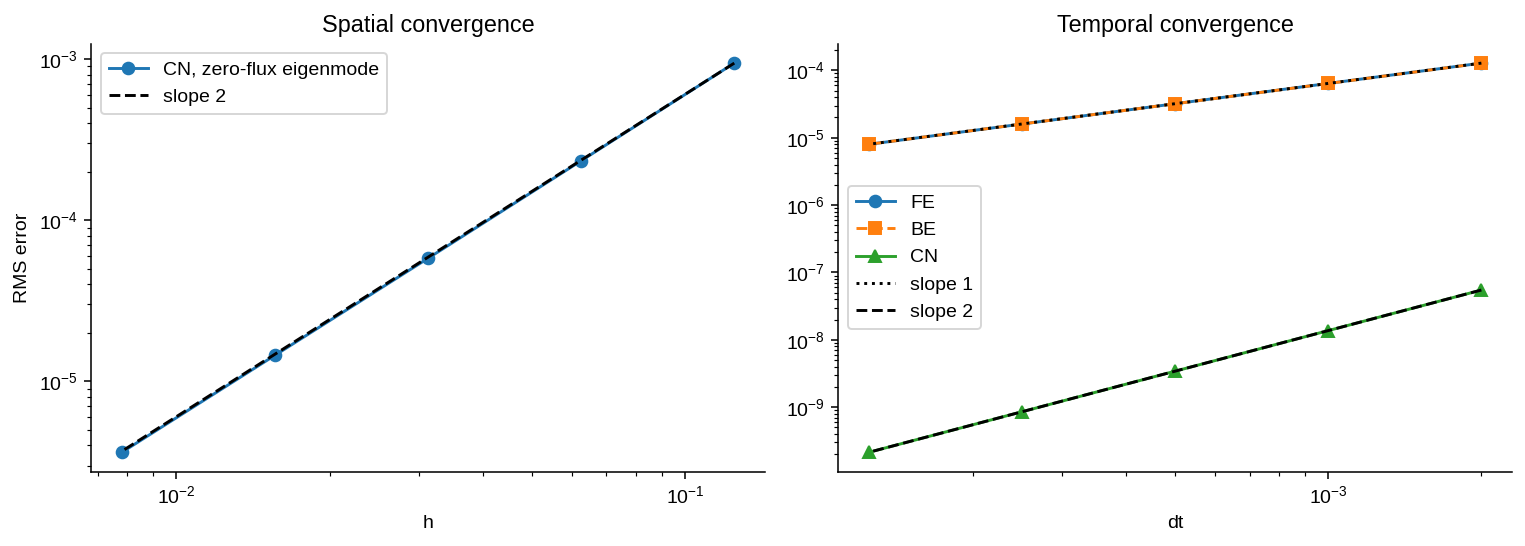

In [ ]:
# ==============================================================================
# VERIFICATION OF THE CONSERVATIVE OPERATOR  (replaces the Dirichlet-only benchmark)
# Tests the *same* code path used in the archipelago runs: zero-flux, cell-centred.
# ==============================================================================
def _cosmode(N):
  x = (np.arange(N) + 0.5) / N
  return np.cos(np.pi * x)[None, :] * np.cos(np.pi * x)[:, None]


D_v, a_v, T_v = 0.05, 0.3, 0.2

# (1) Exact mass conservation on an irregular (masked) domain, alpha = 0
N = 40
mk = np.ones((N, N), bool); mk[:, :5] = False; mk[10:15, 10:30] = False
L_mass = build_operator(mk, 1.0, 0.2, 1 / N, 1 / N)
u_r = np.random.default_rng(0).random(N * N)
print(f"max |column sum of L|  = {np.abs(np.asarray(L_mass.sum(0))).max():.2e}   (0 <=> conservative)")
for sch in ["fe", "be", "cn"]:
  dt_m = 0.5 * explicit_dt_limit(L_mass, 0.0) if sch == "fe" else 1e-3
  u_m, _ = evolve(L_mass, u_r, 0.0, dt_m, int(round(0.02 / dt_m)), sch)
  print(f"  {sch.upper():2s} relative mass drift = {abs(u_m.sum() - u_r.sum()) / u_r.sum():.2e}")

# (2) Spatial order: Neumann eigenmode cos(pi x)cos(pi y) e^{-(2 pi^2 D + alpha) t}
sp_N = [8, 16, 32, 64, 128]
sp_err = []
for N in sp_N:
  h = 1 / N
  L_sp = build_operator(np.ones((N, N), bool), D_v, D_v, h, h)
  n_st = int(np.ceil(T_v / (0.5 * h)))
  u_sp, _ = evolve(L_sp, _cosmode(N), a_v, T_v / n_st, n_st, "cn")
  exact = _cosmode(N).ravel() * np.exp(-(2 * np.pi**2 * D_v + a_v) * T_v)
  sp_err.append(np.sqrt(np.mean((u_sp - exact) ** 2)))
sp_err = np.array(sp_err)

# (3) Temporal order vs the exact *semi-discrete* solution (isolates time error)
N = 32; h = 1 / N
L_t = build_operator(np.ones((N, N), bool), D_v, D_v, h, h)
lam = 2 * (2 - 2 * np.cos(np.pi * h)) / h**2
u0_t = _cosmode(N).ravel()
ex_t = u0_t * np.exp(-(D_v * lam + a_v) * T_v)
n_list = [100, 200, 400, 800, 1600]
t_err = {}
for sch in ["fe", "be", "cn"]:
  t_err[sch] = np.array([
      np.sqrt(np.mean((evolve(L_t, u0_t, a_v, T_v / n, n, sch)[0] - ex_t) ** 2)) for n in n_list
  ])

rows = []
for i in range(1, len(sp_N)):
  rows.append({"N": sp_N[i], "space err (CN)": sp_err[i], "order": np.log2(sp_err[i - 1] / sp_err[i])})
print("\nSpatial convergence (zero-flux eigenmode):"); display(pd.DataFrame(rows))
rows = []
for j in range(1, len(n_list)):
  rows.append({"steps": n_list[j], **{f"{s.upper()} order": np.log2(t_err[s][j - 1] / t_err[s][j]) for s in t_err}})
print("Temporal convergence (observed orders):"); display(pd.DataFrame(rows).round(2))

# (4) Stability: FE below / above the von Neumann (Gershgorin) limit; CN unaffected
rough = np.random.default_rng(0).random(N * N)
lim = explicit_dt_limit(L_t, a_v)
for f in [0.9, 1.5]:
  n_f = int(np.ceil(T_v / (f * lim)))
  print(f"FE at dt = {f:.1f} x limit ({lim:.4f}):  max|u| = {np.abs(evolve(L_t, rough, a_v, T_v / n_f, n_f, 'fe')[0]).max():.3g}")
print(f"CN at dt = 1.5 x limit:           max|u| = {np.abs(evolve(L_t, rough, a_v, T_v / n_f, n_f, 'cn')[0]).max():.3g}")

# (5) Own CG agrees with sparse LU
u_lu, _ = evolve(L_t, rough, a_v, 0.01, 20, "cn", "lu")
u_cg, info = evolve(L_t, rough, a_v, 0.01, 20, "cn", "cg")
print(f"CG vs LU max diff = {np.abs(u_lu - u_cg).max():.1e},  CG iterations/step = {info['cg_iters'] / 20:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hs = 1.0 / np.array(sp_N)
ax[0].loglog(hs, sp_err, "o-", label="CN, zero-flux eigenmode"); ax[0].loglog(hs, sp_err[0] * (hs / hs[0]) ** 2, "k--", label="slope 2")
ax[0].set_xlabel("h"); ax[0].set_ylabel("RMS error"); ax[0].set_title("Spatial convergence"); ax[0].legend()
dts_ = T_v / np.array(n_list)
for s_, st in [("fe", "o-"), ("be", "s--"), ("cn", "^-")]:
  ax[1].loglog(dts_, t_err[s_], st, label=s_.upper())
ax[1].loglog(dts_, t_err["fe"][0] * (dts_ / dts_[0]), "k:", label="slope 1"); ax[1].loglog(dts_, t_err["cn"][0] * (dts_ / dts_[0]) ** 2, "k--", label="slope 2")
ax[1].set_xlabel("dt"); ax[1].set_title("Temporal convergence"); ax[1].legend()
plt.tight_layout(); plt.show()

## 11. Calibration machinery and regional comparison helpers

In [ ]:
def build_region_labels(gdf, ny, nx):
  """Rasterise PSA regions to an int grid: 0 = sea, k = 1..R = region k.
  all_touched=True so thin islands (Batanes, Sulu, Palawan) survive coarse grids.
  Returns (labels, region_names, bounds)."""
  if not (HAS_GEOPANDAS and HAS_RASTERIO and gdf is not None and not gdf.empty):
    raise RuntimeError("Real polygons needed (geopandas + rasterio + geoBoundaries).")
  minx, miny, maxx, maxy = gdf.total_bounds
  tr = Affine.translation(minx, maxy) * Affine.scale(
      (maxx - minx) / nx, -(maxy - miny) / ny
  )
  names = list(dict.fromkeys(gdf["PSA_Region"]))
  # draw big polygons first so small regions (NCR!) are not overwritten by neighbours
  items = sorted(
      [(g, r) for g, r in zip(gdf.geometry, gdf["PSA_Region"]) if g is not None],
      key=lambda t: -t[0].area,
  )
  shapes = [(g, names.index(r) + 1) for g, r in items]
  lab = features.rasterize(
      shapes, out_shape=(ny, nx), transform=tr, fill=0,
      all_touched=True, dtype=np.int32,
  )
  return lab, names, (minx, miny, maxx, maxy)


def region_projector(labels, n_regions):
  """Sparse (R x N) averaging operator: P @ u = mean of u over each region."""
  N = labels.size
  flat = labels.ravel()
  rows, cols = [], []
  vals = []
  for k in range(1, n_regions + 1):
    c = np.flatnonzero(flat == k)
    if c.size == 0:
      continue
    rows.append(np.full(c.size, k - 1))
    cols.append(c)
    vals.append(np.full(c.size, 1.0 / c.size))
  return sp.csr_matrix(
      (np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
      shape=(n_regions, N),
  )


def impulse_response(L, alpha, seed, P, K, dt=0.05):
  """h[r, k] = month-k average of the region-mean of u, for u_t = (L - alpha) u
  started from `seed` (unit-peak shock at the hub at t = 0). Backward Euler
  (monotone, unconditionally stable)."""
  spm = int(round(1.0 / dt))
  rec = [P @ seed.ravel()]

  def cb(step, u):
    if step > 0:
      rec.append(P @ u)

  evolve(L, seed, alpha, dt, (K + 1) * spm, scheme="be", solver="lu", callback=cb)
  rec = np.asarray(rec)
  h = np.empty((P.shape[0], K + 1))
  for k in range(K + 1):
    seg = rec[k * spm : (k + 1) * spm + 1]
    h[:, k] = (seg[:-1] + seg[1:]).sum(axis=0) * dt / 2.0
  return h


# ------------------------------------------------------------------------------
# Empirical side: distributed-lag regressions of every region on the hub's series
# ------------------------------------------------------------------------------
def lag_design(s, K):
  return pd.concat({k: s.shift(k) for k in range(K + 1)}, axis=1)


def empirical_lag_table(y_by_region, s, K, train_end=None):
  """OLS (Householder QR via solve_qr) of y_r(t) on [1, s(t), ..., s(t-K)].
  Returns dict region -> {gamma, a, r2, n}. Fit only on dates <= train_end."""
  X = lag_design(s, K)
  out = {}
  for r, y in y_by_region.items():
    d = pd.concat([y.rename("y"), X], axis=1).dropna()
    if train_end is not None:
      d = d.loc[:train_end]
    if len(d) < 3 * (K + 2):
      continue
    A = np.column_stack([np.ones(len(d)), d[list(range(K + 1))].values])
    b = d["y"].values
    beta = solve_qr(A, b)
    res = b - A @ beta
    r2 = 1.0 - res @ res / ((b - b.mean()) @ (b - b.mean()))
    out[r] = {"a": beta[0], "gamma": beta[1:], "r2": r2, "n": len(d)}
  return out


# ------------------------------------------------------------------------------
# Calibration of (D_land, alpha, c) by nonlinear least squares
# ------------------------------------------------------------------------------
class PDEModel:
  """Holds the geometry once; evaluates the impulse response for (D, alpha)."""

  def __init__(self, mask, dx, dy, seed, P, K, sea_ratio=0.3, dt=0.05, hub_row=None):
    # hub_row: if given, h is divided by the hub region's month-0 response so that the
    # amplitude c is interpretable (~1 when the hub passes the shock through fully)
    # and is not confounded with D (a conservative PDE dilutes the seed as D grows).
    self.hub_row = hub_row
    self.mask, self.dx, self.dy = mask, dx, dy
    self.seed, self.P, self.K = seed, P, K
    self.sea_ratio, self.dt = sea_ratio, dt

  def h(self, D_land, alpha):
    L = build_operator(self.mask, D_land, self.sea_ratio * D_land, self.dx, self.dy)
    h = impulse_response(L, alpha, self.seed, self.P, self.K, self.dt)
    if self.hub_row is not None and h[self.hub_row, 0] > 1e-12:
      h = h / h[self.hub_row, 0]
    return h


def calibrate_pde(model, gamma_emp, rows_used, log10D_starts=(2.0, 3.0, 4.0, 5.0),
                  log10D_bounds=(1.0, 6.0), alpha_bounds=(1e-3, 3.0)):
  """gamma_emp: (R, K+1) empirical lag responses (NaN rows ignored).
  rows_used: boolean (R,) selecting the regions that enter the fit.
  Returns dict with best theta=(log10 D, alpha, c), fit diagnostics and the
  Jacobian SVD (identifiability)."""
  G = gamma_emp[rows_used]

  def resid(x):
    h = model.h(10.0 ** x[0], x[1])[rows_used]
    return (G - x[2] * h).ravel()

  best = None
  for l0 in log10D_starts:
    h0 = model.h(10.0**l0, 0.3)[rows_used]
    c0 = max(1e-3, float((G * h0).sum() / max((h0 * h0).sum(), 1e-12)))
    sol = least_squares(
        resid, x0=[l0, 0.3, c0],
        bounds=([log10D_bounds[0], alpha_bounds[0], 0.0],
                [log10D_bounds[1], alpha_bounds[1], 1e3]),
        x_scale=[1.0, 0.3, max(c0, 0.1)], method="trf",
    )
    if best is None or sol.cost < best.cost:
      best = sol
  J = best.jac
  sv = np.linalg.svd(J, compute_uv=False)
  dof = max(1, G.size - 3)
  s2 = 2.0 * best.cost / dof
  cov = s2 * np.linalg.pinv(J.T @ J)
  se = np.sqrt(np.clip(np.diag(cov), 0, None))
  x = best.x
  return {
      "log10D": x[0], "D": 10.0 ** x[0], "alpha": x[1], "c": x[2],
      "se": dict(zip(["log10D", "alpha", "c"], se)),
      "rmse": float(np.sqrt(2.0 * best.cost / G.size)),
      "jac_sv": sv, "jac_cond": float(sv[0] / max(sv[-1], 1e-300)),
      "at_D_bound": bool(x[0] >= log10D_bounds[1] - 1e-6 or x[0] <= log10D_bounds[0] + 1e-6),
      "at_alpha_bound": bool(x[1] <= alpha_bounds[0] + 1e-9 or x[1] >= alpha_bounds[1] - 1e-9),
  }


def predict_lag_model(s, K, a, gamma_row):
  """yhat(t) = a + sum_k gamma_k s(t-k) on the index of s."""
  X = lag_design(s, K)
  return a + (X.values * gamma_row[None, :]).sum(axis=1), X.index


def evaluate_regional_models(y_by_region, s, K, train_ratio, emp_train, h_pde, c_pde,
                             region_to_row):
  """Chronological hold-out comparison of three regional models
     instant : yhat = a_r + c0 * s(t)              (no spatial delay, 1 global parameter)
     pde     : yhat = a_r + c * sum_k h_r(k) s(t-k) (3 global parameters)
     free    : yhat = a_r + sum_k gamma_r(k) s(t-k) (K+1 parameters per region)"""
  X = lag_design(s, K)
  idx_all = s.dropna().index
  train_end = idx_all[int(np.floor(len(idx_all) * train_ratio)) - 1]

  # global c0 for 'instant' from the training data (least squares through the a_r)
  num = den = 0.0
  for r, y in y_by_region.items():
    if r not in emp_train:
      continue
    d = pd.concat([y.rename("y"), s.rename("s")], axis=1).dropna().loc[:train_end]
    yc = d["y"] - emp_train[r]["a"]
    num += float((yc * d["s"]).sum())
    den += float((d["s"] ** 2).sum())
  c0 = num / den

  rows = []
  for r, y in y_by_region.items():
    if r not in emp_train or r not in region_to_row:
      continue
    d = pd.concat([y.rename("y"), X], axis=1).dropna()
    te = d.loc[d.index > train_end]
    if len(te) < 6:
      continue
    Xte = te[list(range(K + 1))].values
    a = emp_train[r]["a"]
    preds = {
        "instant": a + c0 * Xte[:, 0],
        "pde": a + c_pde * (Xte @ h_pde[region_to_row[r], : K + 1]),
        "free": a + Xte @ emp_train[r]["gamma"],
        "intercept only": np.full(len(te), a),
    }
    row = {"region": r, "n_test": len(te)}
    for name, p in preds.items():
      row[name] = float(np.sqrt(np.mean((te["y"].values - p) ** 2)))
    rows.append(row)
  return pd.DataFrame(rows), c0, train_end

In [ ]:
def grid_nx_for(ny, bounds):
  """nx giving (nearly) square cells in km."""
  minx, miny, maxx, maxy = bounds
  return int(round(ny * (maxx - minx) * np.cos(np.deg2rad(12.5)) / (maxy - miny)))


def rel_l2(a, b):
  return float(np.linalg.norm(a - b) / np.linalg.norm(b))


def scheme_comparison(L, seed, alpha, T, dt_ref=0.002, dts=(0.4, 0.2, 0.1, 0.05)):
  """Forward Euler vs Backward Euler vs Crank-Nicolson (LU and own-CG) on the
  real-geometry operator. Reference: CN with a tiny step. Reports error, cost,
  CG iterations and the explicit stability limit."""
  u_ref, _ = evolve(L, seed, alpha, dt_ref, int(round(T / dt_ref)), "cn", "lu")
  lim = explicit_dt_limit(L, alpha)
  rows = [{"scheme": "(reference CN)", "solver": "lu", "dt": dt_ref,
           "steps": int(round(T / dt_ref)), "rel_L2_err": 0.0, "time_s": np.nan,
           "cg_iters/step": np.nan, "note": f"FE dt limit = {lim:.4f} mo"}]
  for scheme, solver in [("fe", "-"), ("be", "lu"), ("be", "cg"), ("cn", "lu"), ("cn", "cg")]:
    for dt in dts:
      n = int(round(T / dt))
      if scheme == "fe":
        if T / (0.9 * lim) > 200000 and dt > lim:
          rows.append({"scheme": "FE", "solver": "-", "dt": np.nan, "steps": int(T / (0.9 * lim)),
                       "rel_L2_err": np.nan, "time_s": np.nan, "cg_iters/step": np.nan,
                       "note": "skipped: stable explicit step too small (stiff)"})
          break
        if dt > lim:
          n_use = int(np.ceil(T / (0.9 * lim)))      # use the largest stable step
          if n_use > 200000:
            continue
          dt_use, note = T / n_use, f"dt={dt} unstable -> used {T/n_use:.4f}"
        else:
          n_use, dt_use, note = n, dt, ""
        if dt != dts[0] and dt > lim:
          continue
      else:
        n_use, dt_use, note = n, dt, ""
      t0 = time.perf_counter()
      u, info = evolve(L, seed, alpha, dt_use, n_use, scheme, "lu" if solver == "-" else solver)
      el = time.perf_counter() - t0
      rows.append({"scheme": scheme.upper(), "solver": solver, "dt": round(dt_use, 4),
                   "steps": n_use, "rel_L2_err": rel_l2(u, u_ref),
                   "time_s": el, "cg_iters/step": info["cg_iters"] / n_use if solver == "cg" else np.nan,
                   "note": note})
  return pd.DataFrame(rows), lim


def region_means_over_time(L, seed, alpha, P, T, dt):
  rec = []
  evolve(L, seed, alpha, dt, int(round(T / dt)), "cn", "lu",
         callback=lambda k, u: rec.append(P @ u))
  return np.asarray(rec)


def arrival_time(ts, series, thresh):
  """First time the series reaches thresh (linear interpolation); NaN if never."""
  above = np.flatnonzero(series >= thresh)
  if above.size == 0:
    return np.nan
  j = above[0]
  if j == 0:
    return float(ts[0])
  f = (thresh - series[j - 1]) / (series[j] - series[j - 1])
  return float(ts[j - 1] + f * (ts[j] - ts[j - 1]))


def resolution_study(gdf, D_land, alpha, sea_ratio, sizes, targets, T=6.0, dt=0.02,
                     sigma_km=60.0, frac=0.10, snap_t=3.0):
  """Grid-refinement study on the real archipelago. For each ny: rasterise,
  build the operator at fixed *physical* D (km^2/month), run CN with a small
  fixed dt, and record (i) arrival times of the shock in target regions,
  (ii) region-mean profile at t=snap_t. Errors are measured against the finest grid."""
  out, profiles = [], {}
  hub_lat, hub_lon = HUBS_LATLON["NCR"]
  for ny in sizes:
    probe_bounds = tuple(gdf.total_bounds)
    nx = grid_nx_for(ny, probe_bounds)
    lab, names, bounds = build_region_labels(gdf, ny, nx)
    mask = lab > 0
    dx, dy = grid_spacing_km(bounds, ny, nx)
    L = build_operator(mask, D_land, sea_ratio * D_land, dx, dy)
    seed = gaussian_seed_km(bounds, ny, nx, hub_lat, hub_lon, sigma_km).ravel()
    P = region_projector(lab, len(names))
    rec = region_means_over_time(L, seed, alpha, P, T, dt)
    ts = np.arange(rec.shape[0]) * dt
    row = {"ny": ny, "nx": nx, "cell_km": round(0.5 * (dx + dy), 1), "land_cells": int(mask.sum()),
           "n_dof": ny * nx}
    for label, key in targets.items():
      ridx = [i for i, nm in enumerate(names) if key in nm]
      if ridx:
        ser = rec[:, ridx[0]]
        row[f"arrival {label} (mo)"] = (
            arrival_time(ts, ser, frac * ser.max()) if ser.max() > 1e-8 else np.nan
        )
    profiles[ny] = pd.Series(rec[int(round(snap_t / dt))], index=names)
    out.append(row)
  df = pd.DataFrame(out)
  ref = profiles[sizes[-1]]
  errs = []
  for ny in sizes:
    common = profiles[ny].index.intersection(ref.index)
    errs.append(rel_l2(profiles[ny][common].values, ref[common].values))
  df["rel_L2 vs finest (region means @ t=%.0f)" % snap_t] = errs
  return df, profiles


def observed_order(df, err_col, h_col="cell_km"):
  """Least-squares slope of log(err) vs log(h), excluding the reference grid."""
  d = df.iloc[:-1]
  d = d[d[err_col] > 0]
  if len(d) < 2:
    return np.nan
  return float(np.polyfit(np.log(d[h_col]), np.log(d[err_col]), 1)[0])

## 12. Item 2 — Does fuel inflation reach other regions with a delay? (empirical lag responses)

Grid 45x33, cell ~ 41 km, land cells = 425
Regions with data but no polygon (excluded from the spatial analysis): ['NIR (Est. 2024)']
Regions with zero cells at this resolution: []


,region,dist_km,gamma0,gamma1,gamma2,gamma3,R2,n
0,NCR,0.000,1.000,-0.000,-0.000,-0.000,1.000,102
1,Region IV-A (CALABARZON),91.634,0.714,0.283,-0.068,0.013,0.868,102
2,Region III (C. Luzon),123.224,0.561,0.301,-0.169,0.039,0.892,102
3,Region I (Ilocos),276.788,0.716,0.269,-0.134,-0.004,0.891,102
4,CAR,328.963,0.354,0.037,0.068,-0.002,0.737,102
5,Region V (Bicol),330.938,0.785,0.145,-0.032,0.022,0.957,102
6,Region VI (W. Visayas),405.742,0.778,0.114,-0.071,-0.003,0.937,102
7,MIMAROPA,408.931,0.618,0.042,-0.029,0.003,0.811,102
8,Region II (Cagayan),448.963,0.727,0.142,-0.005,-0.006,0.856,102
9,Region VIII (E. Visayas),552.044,0.416,0.410,-0.139,0.180,0.766,102


Spearman(distance, gamma0) = -0.27  (p = 0.286)
Spearman(distance, gamma1) = -0.12  (p = 0.653)

Reading: if gamma0 stays ~constant with distance and gamma1..3 ~ 0, monthly fuel CPI is effectively national and a diffusion delay is NOT identifiable at monthly resolution (use weekly DOE prices).


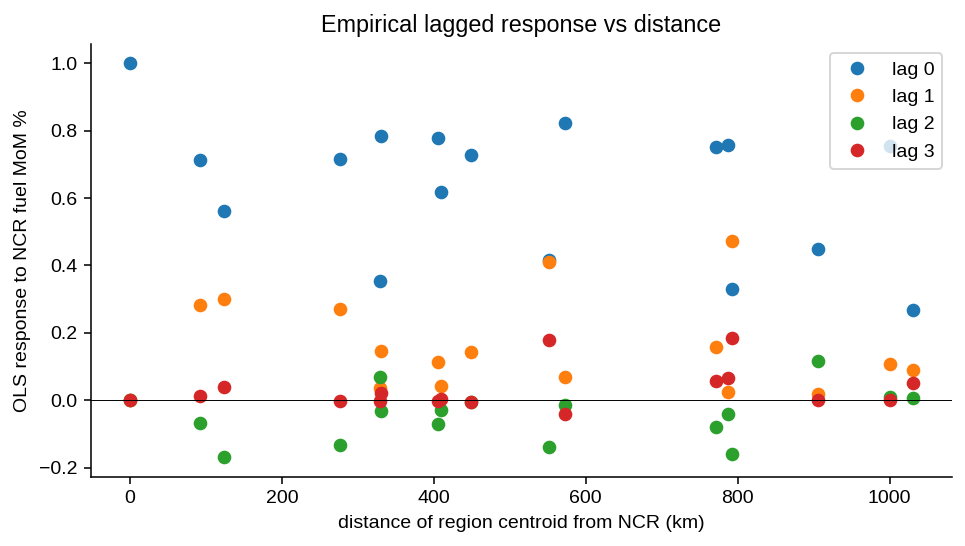

In [ ]:
# ==============================================================================
# ITEM 2 (data side): does fuel inflation reach other regions with a delay?
# Distributed-lag regression (Householder-QR via solve_qr) of every regional
# Liquid-Fuels MoM series on the NCR (hub) series, lags 0..K.
# ==============================================================================
from scipy.stats import spearmanr

HUB_REGION = "National Capital Region (NCR)"
FUEL = "Liquid Fuels"
K_FIT = 3
CAL_NY = 45                       # ~40 km cells: cheap enough for hundreds of solves

assert ph_gdf is not None, "Needs real polygons (geoBoundaries) -- rerun the geometry cell."
CAL_NX = grid_nx_for(CAL_NY, tuple(ph_gdf.total_bounds))
labels_cal, reg_names, bounds_cal = build_region_labels(ph_gdf, CAL_NY, CAL_NX)
mask_cal = labels_cal > 0
dx_cal, dy_cal = grid_spacing_km(bounds_cal, CAL_NY, CAL_NX)
P_cal = region_projector(labels_cal, len(reg_names))
hub_lat, hub_lon = HUBS_LATLON["NCR"]
seed_cal = gaussian_seed_km(bounds_cal, CAL_NY, CAL_NX, hub_lat, hub_lon, 60.0).ravel()
region_to_row = {n: i for i, n in enumerate(reg_names)}

empty = [n for n in reg_names if (labels_cal == region_to_row[n] + 1).sum() == 0]
no_poly = [r for r in MAIN_REGIONS if r not in reg_names]
print(f"Grid {CAL_NY}x{CAL_NX}, cell ~ {0.5*(dx_cal+dy_cal):.0f} km, land cells = {mask_cal.sum()}")
print("Regions with data but no polygon (excluded from the spatial analysis):", [SHORT_NAMES.get(r, r) for r in no_poly])
print("Regions with zero cells at this resolution:", empty)

y_by_region = {r: region_mom[r][FUEL].dropna() for r in reg_names if r in region_mom}
s_hub = region_mom[HUB_REGION][FUEL].dropna()
idx_s = s_hub.index
TRAIN_END = idx_s[int(np.floor(len(idx_s) * TRAIN_RATIO)) - 1]
emp_train = empirical_lag_table(y_by_region, s_hub, K_FIT, train_end=TRAIN_END)
emp_all = empirical_lag_table(y_by_region, s_hub, K_FIT)

XXc, YYc = cell_centers_km(bounds_cal, CAL_NY, CAL_NX)
cent = {n: (XXc[labels_cal == k + 1].mean(), YYc[labels_cal == k + 1].mean()) for n, k in region_to_row.items() if (labels_cal == k + 1).any()}
hx, hy = cent[HUB_REGION]
rows = []
for n in reg_names:
  if n in emp_all and n in cent:
    g = emp_all[n]["gamma"]
    rows.append({"region": SHORT_NAMES.get(n, n), "dist_km": float(np.hypot(cent[n][0] - hx, cent[n][1] - hy)),
                 **{f"gamma{k}": g[k] for k in range(K_FIT + 1)}, "R2": emp_all[n]["r2"], "n": emp_all[n]["n"]})
emp_df = pd.DataFrame(rows).sort_values("dist_km").reset_index(drop=True)
display(emp_df.round(3))

for k in range(2):
  rho, p = spearmanr(emp_df["dist_km"], emp_df[f"gamma{k}"])
  print(f"Spearman(distance, gamma{k}) = {rho:+.2f}  (p = {p:.3f})")
print("\nReading: if gamma0 stays ~constant with distance and gamma1..3 ~ 0, monthly fuel CPI is effectively "
      "national and a diffusion delay is NOT identifiable at monthly resolution (use weekly DOE prices).")

fig, ax = plt.subplots(figsize=(7, 4))
for k in range(K_FIT + 1):
  ax.plot(emp_df["dist_km"], emp_df[f"gamma{k}"], "o", label=f"lag {k}")
ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("distance of region centroid from NCR (km)")
ax.set_ylabel("OLS response to NCR fuel MoM %"); ax.legend(); ax.set_title("Empirical lagged response vs distance")
plt.tight_layout(); plt.show()

### Calibrate $(D,\alpha,c)$ by nonlinear least squares; compare with rival models on held-out months

Regions in the fit: 17  (hub region included: its gamma is (1,0,0,0) by construction and anchors c)
D     = 1e+06 km^2/month   (log10 D = 6.00 +/- 0.32)
alpha = 0.626 /month    (+/- 0.214)
c     = 1.694               (+/- 0.170)   [hub-normalised amplitude; ~1 = full pass-through at the hub]
fit RMSE on gamma = 0.228;  Jacobian singular values = [1.8776 1.1927 0.6701],  cond(J) = 2.8
Diffusion length over 1 month: sqrt(4 D t) = 2000 km  (NCR->Cebu ~ 570 km, NCR->Davao ~ 950 km)

Sensitivity to the sea/land diffusivity ratio:


,D_sea/D_land,D,alpha,c,RMSE,D at bound
0,0.1,1000000.0,0.596,1.634,0.220,True
1,0.3,1000000.0,0.626,1.694,0.228,True
2,1.0,1000000.0,0.672,1.740,0.229,True



Held-out RMSE (%-points of regional fuel MoM), test months after Jan 2025:


,region,n_test,instant,pde,free,intercept only
0,BARMM,21,7.553,2.210,6.669,4.297
1,CAR,21,7.117,4.238,3.153,3.856
2,NCR,21,2.915,9.924,0.000,13.323
3,Region I (Ilocos),21,4.817,5.497,4.080,11.636
4,Region II (Cagayan),21,2.732,5.010,3.028,10.323
5,Region III (C. Luzon),21,5.337,6.134,4.888,10.778
6,Region IV-A (CALABARZON),21,4.514,3.744,5.932,9.942
7,MIMAROPA,21,4.575,5.134,5.455,7.498
8,Region IX (Zamboanga),21,2.518,8.192,2.490,11.015
9,Region V (Bicol),21,2.363,5.008,2.744,10.567


instant           4.748
pde               6.039
free              4.278
intercept only    9.328

  instant = no spatial delay (1 param) | pde = calibrated diffusion (3 params) | free = per-region OLS lags (4 params/region)


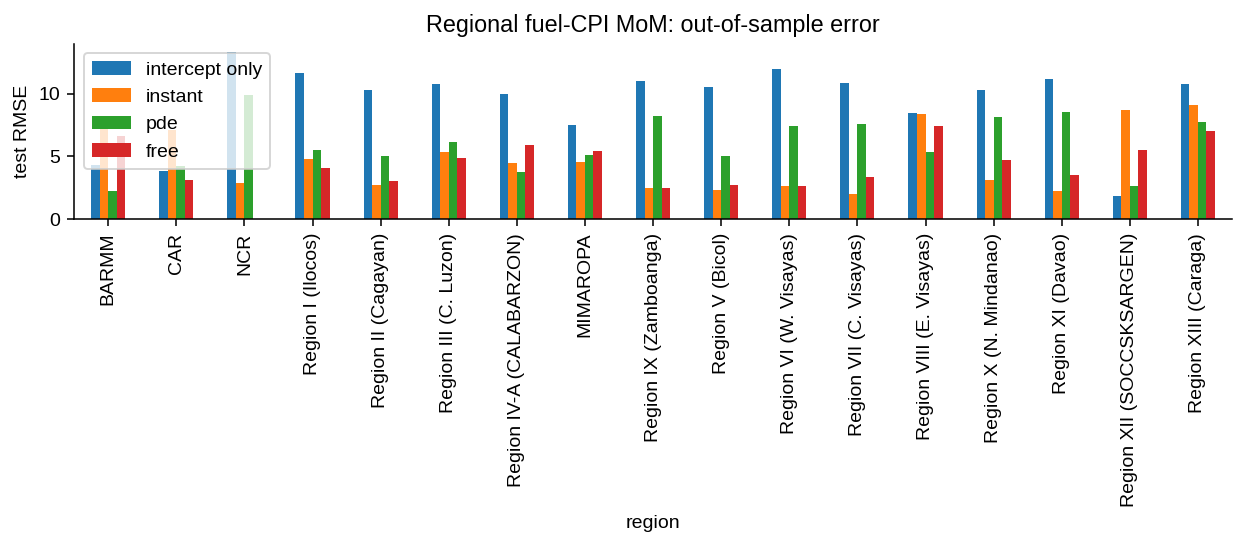

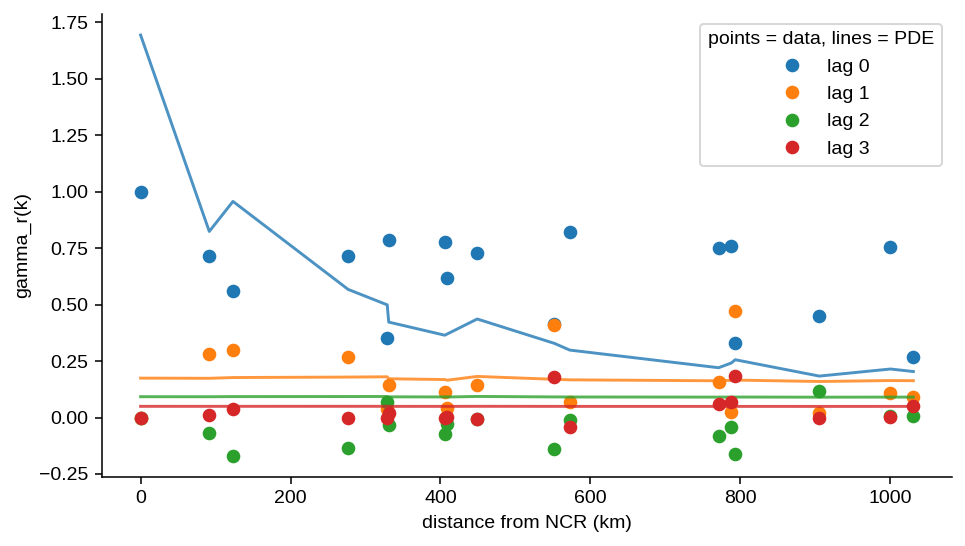

In [ ]:
# ==============================================================================
# ITEM 2: calibrate (D, alpha, c) of the PDE to the regional lag responses by
# nonlinear least squares, then compare against rival models on held-out months.
# ==============================================================================
SEA_RATIO = 0.3                   # D_sea / D_land (assumption; sensitivity below)
HUB_ROW = region_to_row[HUB_REGION]
pde_model = PDEModel(mask_cal, dx_cal, dy_cal, seed_cal, P_cal, K_FIT, sea_ratio=SEA_RATIO, hub_row=HUB_ROW)

G_train = np.full((len(reg_names), K_FIT + 1), np.nan)
used = np.zeros(len(reg_names), bool)
for n, e in emp_train.items():
  if n in region_to_row and (labels_cal == region_to_row[n] + 1).any():
    G_train[region_to_row[n]] = e["gamma"]; used[region_to_row[n]] = True
print(f"Regions in the fit: {used.sum()}  (hub region included: its gamma is (1,0,0,0) by construction and anchors c)")

fit = calibrate_pde(pde_model, G_train, used)
print(f"D     = {fit['D']:.3g} km^2/month   (log10 D = {fit['log10D']:.2f} +/- {fit['se']['log10D']:.2f})")
print(f"alpha = {fit['alpha']:.3f} /month    (+/- {fit['se']['alpha']:.3f})")
print(f"c     = {fit['c']:.3f}               (+/- {fit['se']['c']:.3f})   [hub-normalised amplitude; ~1 = full pass-through at the hub]")
print(f"fit RMSE on gamma = {fit['rmse']:.3f};  Jacobian singular values = {np.round(fit['jac_sv'], 4)},  cond(J) = {fit['jac_cond']:.1f}")
if fit["at_D_bound"]:
  print("WARNING: D is at a bound -> the data cannot pin D down (response is ~instantaneous or ~absent).")
if fit["at_alpha_bound"]:
  print("WARNING: alpha is at a bound.")
print(f"Diffusion length over 1 month: sqrt(4 D t) = {np.sqrt(4*fit['D']):.0f} km  (NCR->Cebu ~ 570 km, NCR->Davao ~ 950 km)")

# sensitivity to the one assumption we had to make
sens = []
for ratio in [0.1, 0.3, 1.0]:
  m_ = PDEModel(mask_cal, dx_cal, dy_cal, seed_cal, P_cal, K_FIT, sea_ratio=ratio, hub_row=HUB_ROW)
  f_ = calibrate_pde(m_, G_train, used)
  sens.append({"D_sea/D_land": ratio, "D": f_["D"], "alpha": f_["alpha"], "c": f_["c"], "RMSE": f_["rmse"], "D at bound": f_["at_D_bound"]})
print("\nSensitivity to the sea/land diffusivity ratio:"); display(pd.DataFrame(sens).round(3))

# chronological hold-out comparison
h_fit = pde_model.h(fit["D"], fit["alpha"])
cmp_df, c0_inst, te_start = evaluate_regional_models(
    y_by_region, s_hub, K_FIT, TRAIN_RATIO, emp_train, h_fit, fit["c"], region_to_row)
cmp_df["region"] = cmp_df["region"].map(lambda r: SHORT_NAMES.get(r, r))
print(f"\nHeld-out RMSE (%-points of regional fuel MoM), test months after {te_start.strftime('%b %Y')}:")
display(cmp_df.round(3))
print(cmp_df[["instant", "pde", "free", "intercept only"]].mean().round(3).to_string())
print("\n  instant = no spatial delay (1 param) | pde = calibrated diffusion (3 params) | "
      "free = per-region OLS lags (4 params/region)")

fig, ax = plt.subplots(figsize=(9, 4))
cmp_df.set_index("region")[["intercept only", "instant", "pde", "free"]].plot.bar(ax=ax)
ax.set_ylabel("test RMSE"); ax.set_title("Regional fuel-CPI MoM: out-of-sample error"); plt.tight_layout(); plt.show()

# model-implied lag profile vs data
fig, ax = plt.subplots(figsize=(7, 4))
for k in range(K_FIT + 1):
  rr = [(cent_d, fit["c"] * h_fit[region_to_row[n], k], emp_all[n]["gamma"][k]) for n, cent_d in
        [(n, np.hypot(cent[n][0] - hx, cent[n][1] - hy)) for n in reg_names if n in emp_all and n in cent]]
  rr.sort()
  ax.plot([a for a, _, _ in rr], [b for _, b, _ in rr], "-", color=f"C{k}", alpha=0.8)
  ax.plot([a for a, _, _ in rr], [c_ for _, _, c_ in rr], "o", color=f"C{k}", label=f"lag {k}")
ax.set_xlabel("distance from NCR (km)"); ax.set_ylabel("gamma_r(k)"); ax.legend(title="points = data, lines = PDE")
plt.tight_layout(); plt.show()

D_USE, ALPHA_USE = fit["D"], fit["alpha"]

## 13. Item 1 — Coupling: PDE spread × Part A pass-through → regional headline-CPI impact

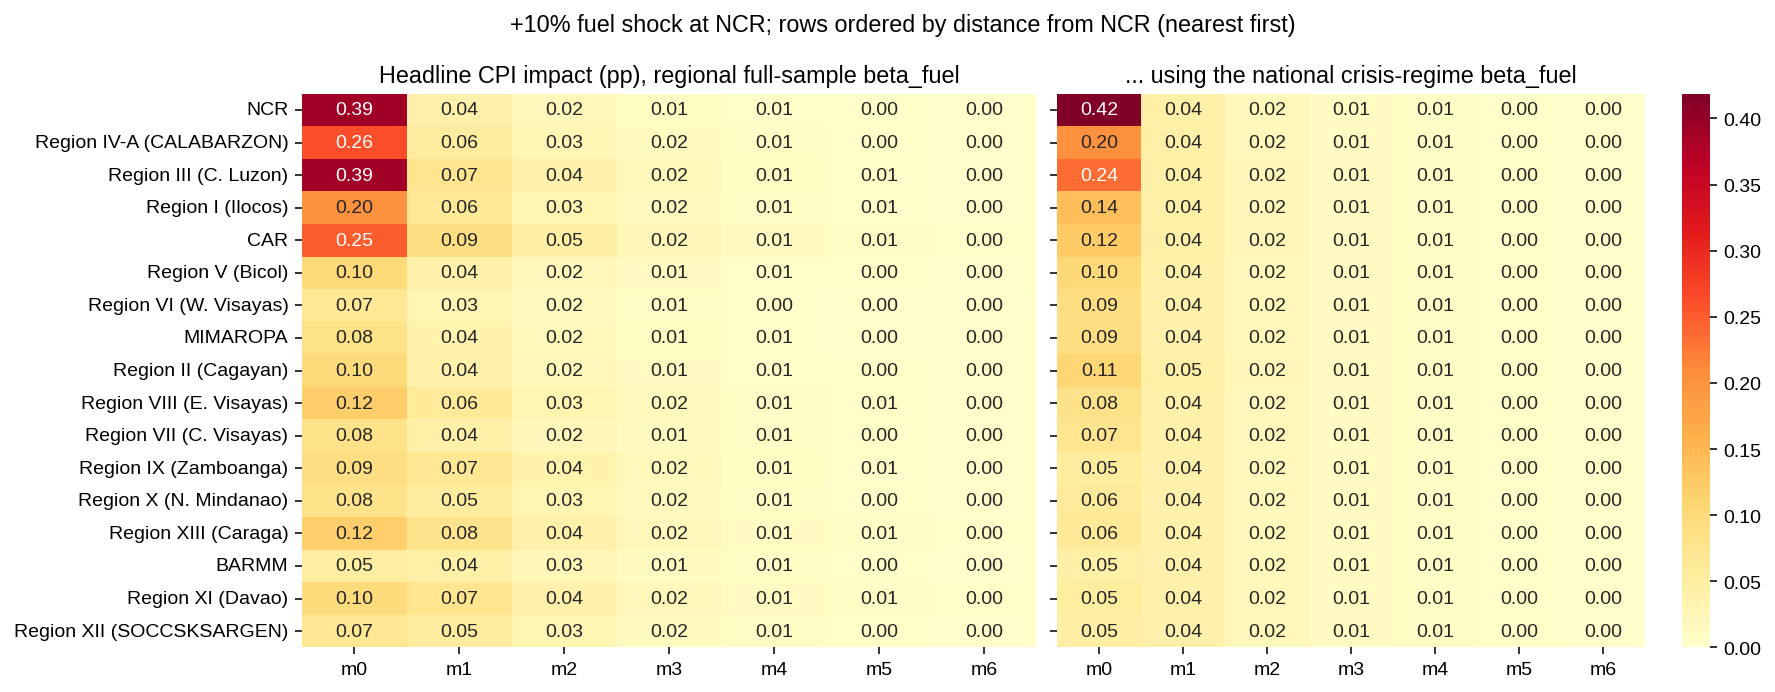

,"cum. impact, regional beta (pp)","cum. impact, crisis beta (pp)",peak month
NCR,0.475,0.509,0
Region IV-A (CALABARZON),0.379,0.294,0
Region III (C. Luzon),0.539,0.328,0
Region I (Ilocos),0.337,0.232,0
CAR,0.437,0.215,0
Region V (Bicol),0.190,0.194,0
Region VI (W. Visayas),0.131,0.179,0
MIMAROPA,0.163,0.179,0
Region II (Cagayan),0.187,0.200,0
Region VIII (E. Visayas),0.251,0.170,0


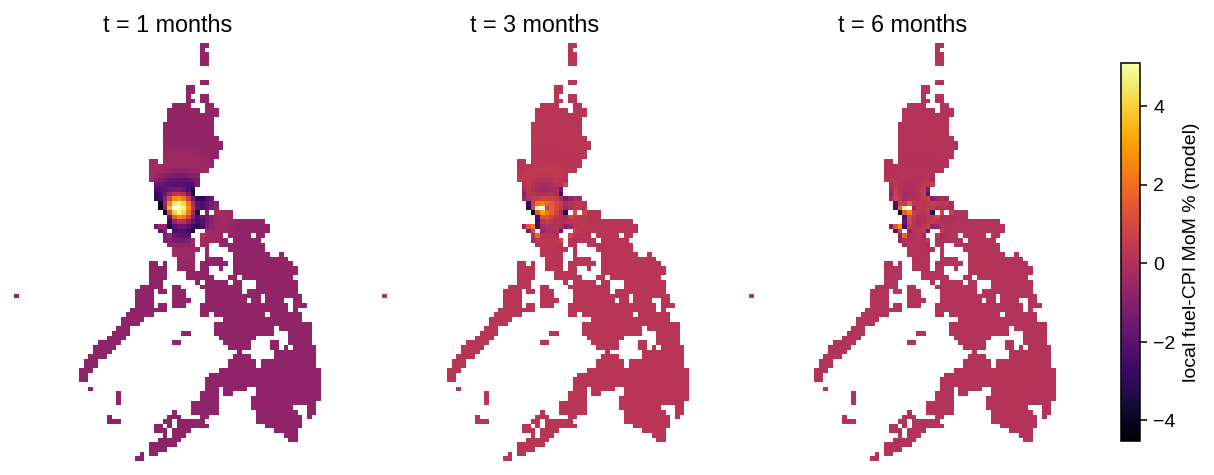

In [ ]:
# ==============================================================================
# ITEM 1: connect Part A and Part B.
#   Part B (PDE): where does a local fuel shock go, and when?   -> gamma_r(k) = c * h_r(k)
#   Part A (LS) : how much headline CPI does 1% of fuel inflation add? -> beta_fuel
#   headline impact_r(k) = beta_fuel_r * gamma_r(k) * shock
# ==============================================================================
SHOCK = 10.0          # hypothetical +10% MoM jump in Liquid-Fuels CPI at the NCR hub
K_SCEN = 6
model_scen = PDEModel(mask_cal, dx_cal, dy_cal, seed_cal, P_cal, K_SCEN, sea_ratio=SEA_RATIO, hub_row=HUB_ROW)
gamma_model = fit["c"] * model_scen.h(fit["D"], fit["alpha"])        # (R, K_SCEN+1)

beta_nat_full = piecewise_betas["Full Sample (2018–2026)"][1]
beta_nat_crisis = piecewise_betas["Unstable / Crisis Regime"][1]
beta_reg = np.array([regional_betas[n]["beta_fuel"] if n in regional_betas else beta_nat_full for n in reg_names])

regs_plot = [n for n in reg_names if (labels_cal == region_to_row[n] + 1).any()]
order = sorted(regs_plot, key=lambda n: np.hypot(cent[n][0] - hx, cent[n][1] - hy))
rowsel = [region_to_row[n] for n in order]
short = [SHORT_NAMES.get(n, n) for n in order]
months = [f"m{k}" for k in range(K_SCEN + 1)]

imp_reg = pd.DataFrame(SHOCK * beta_reg[rowsel, None] * gamma_model[rowsel], index=short, columns=months)
imp_crisis = pd.DataFrame(SHOCK * beta_nat_crisis * gamma_model[rowsel], index=short, columns=months)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
vmax = max(imp_reg.values.max(), imp_crisis.values.max())
sns.heatmap(imp_reg, ax=axes[0], cmap="YlOrRd", vmin=0, vmax=vmax, annot=True, fmt=".2f", cbar=False)
axes[0].set_title("Headline CPI impact (pp), regional full-sample beta_fuel")
sns.heatmap(imp_crisis, ax=axes[1], cmap="YlOrRd", vmin=0, vmax=vmax, annot=True, fmt=".2f")
axes[1].set_title("... using the national crisis-regime beta_fuel")
fig.suptitle(f"+{SHOCK:.0f}% fuel shock at NCR; rows ordered by distance from NCR (nearest first)")
plt.tight_layout(); plt.show()

cum = pd.DataFrame({"cum. impact, regional beta (pp)": imp_reg.sum(axis=1),
                    "cum. impact, crisis beta (pp)": imp_crisis.sum(axis=1),
                    "peak month": imp_reg.values.argmax(axis=1)}); display(cum.round(3))

# spatial snapshots of the local fuel shock on a finer grid (north-up)
FINE_NY = 90
FINE_NX = grid_nx_for(FINE_NY, tuple(ph_gdf.total_bounds))
lab_f, _, b_f = build_region_labels(ph_gdf, FINE_NY, FINE_NX)
mk_f = lab_f > 0
dxf, dyf = grid_spacing_km(b_f, FINE_NY, FINE_NX)
L_f = build_operator(mk_f, fit["D"], SEA_RATIO * fit["D"], dxf, dyf)
seed_f = gaussian_seed_km(b_f, FINE_NY, FINE_NX, hub_lat, hub_lon, 60.0).ravel()
snaps_t = {1: None, 3: None, 6: None}
dt_s = 0.05
def _cb(k, u):
  for tt in snaps_t:
    if k == int(round(tt / dt_s)):
      snaps_t[tt] = u.reshape(FINE_NY, FINE_NX).copy()
evolve(L_f, seed_f, fit["alpha"], dt_s, int(round(6 / dt_s)), "cn", "lu", callback=_cb)
raw_h = PDEModel(mask_cal, dx_cal, dy_cal, seed_cal, P_cal, 0, sea_ratio=SEA_RATIO).h(fit["D"], fit["alpha"])
amp_map = fit["c"] * SHOCK / raw_h[HUB_ROW, 0]        # same scaling that defines gamma_r(k)
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
for ax, tt in zip(axes, snaps_t):
  im = ax.imshow(np.where(mk_f, snaps_t[tt] * amp_map, np.nan), cmap="inferno", origin="upper")
  ax.set_title(f"t = {tt} months"); ax.axis("off")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7, label="local fuel-CPI MoM % (model)")
plt.show()

## 14. Item 3 — Implicit schemes on the real archipelago (sparse LU vs own CG)

In [ ]:
# ==============================================================================
# ITEM 3: implicit time stepping on the real archipelago.  Each implicit step is
# one sparse SPD solve (I - theta dt (L - alpha I)) u+ = rhs, done by LU and by our CG.
# ==============================================================================
SCH_NY = 90
SCH_NX = grid_nx_for(SCH_NY, tuple(ph_gdf.total_bounds))
lab_s, _, b_s = build_region_labels(ph_gdf, SCH_NY, SCH_NX)
mk_s = lab_s > 0
dxs, dys = grid_spacing_km(b_s, SCH_NY, SCH_NX)
D_STIFF = float(min(D_USE, 2e4))          # cap: keeps the explicit scheme runnable for the comparison
L_s = build_operator(mk_s, D_STIFF, SEA_RATIO * D_STIFF, dxs, dys)
seed_s = gaussian_seed_km(b_s, SCH_NY, SCH_NX, hub_lat, hub_lon, 60.0).ravel()
print(f"{SCH_NY}x{SCH_NX} grid, {mk_s.sum()} land cells, D = {D_STIFF:.3g} km^2/mo, alpha = {ALPHA_USE:.2f}/mo")
sch_df, lim_fe = scheme_comparison(L_s, seed_s, ALPHA_USE, T=6.0)
display(sch_df.round(5))
print(f"Explicit (FE) stability limit dt <= {lim_fe:.4f} months; implicit schemes are unconditionally stable "
      "(dt is chosen for accuracy, not stability).")
print("Reading: CN is 2nd order and is the best accuracy/cost; BE is monotone but 1st order; CG matches LU "
      "to solver tolerance, with iteration counts that fall as dt shrinks (better-conditioned systems).")

90x66 grid, 1331 land cells, D = 2e+04 km^2/mo, alpha = 0.63/mo


,scheme,solver,dt,steps,rel_L2_err,time_s,cg_iters/step,note
0,(reference CN),lu,0.0020,3000,0.00000,NaN,NaN,FE dt limit = 0.0052 mo
1,FE,-,0.0047,1287,0.00683,0.06187,NaN,dt=0.4 unstable -> used 0.0047
2,BE,lu,0.4000,15,0.66502,0.04085,NaN,
3,BE,lu,0.2000,30,0.31352,0.05221,NaN,
4,BE,lu,0.1000,60,0.15185,0.08422,NaN,
5,BE,lu,0.0500,120,0.07468,0.14855,NaN,
6,BE,cg,0.4000,15,0.66502,0.18430,129.13333,
7,BE,cg,0.2000,30,0.31352,0.29548,97.13333,
8,BE,cg,0.1000,60,0.15185,0.44112,70.45000,
9,BE,cg,0.0500,120,0.07468,0.54750,50.27500,


Explicit (FE) stability limit dt <= 0.0052 months; implicit schemes are unconditionally stable (dt is chosen for accuracy, not stability).
Reading: CN is 2nd order and is the best accuracy/cost; BE is monotone but 1st order; CG matches LU to solver tolerance, with iteration counts that fall as dt shrinks (better-conditioned systems).


## 15. Item 4 — Grid-refinement study on the real archipelago

,ny,nx,cell_km,land_cells,n_dof,arrival C. Visayas (mo),arrival Davao (mo),arrival N. Mindanao (mo),rel_L2 vs finest (region means @ t=3)
0,30,22,61.1,223,660,0.5181,1.5903,1.0117,0.2406
1,45,33,40.7,425,1485,0.5715,1.6495,1.0690,0.1770
2,60,44,30.6,675,2640,0.5950,1.6968,1.2020,0.1445
3,90,66,20.4,1331,5940,0.6765,1.7831,1.2587,0.0923
4,135,98,13.7,2579,13230,0.7271,1.8989,1.3823,0.0449
5,180,131,10.2,4215,23580,0.7983,1.9942,1.5037,0.0000


Observed convergence rate in cell size: ~ h^1.10
Reading: the rate is limited by the *geometry* (the land/sea mask and region borders change with ny), not by the stencil, which is 2nd order (see the verification cell).


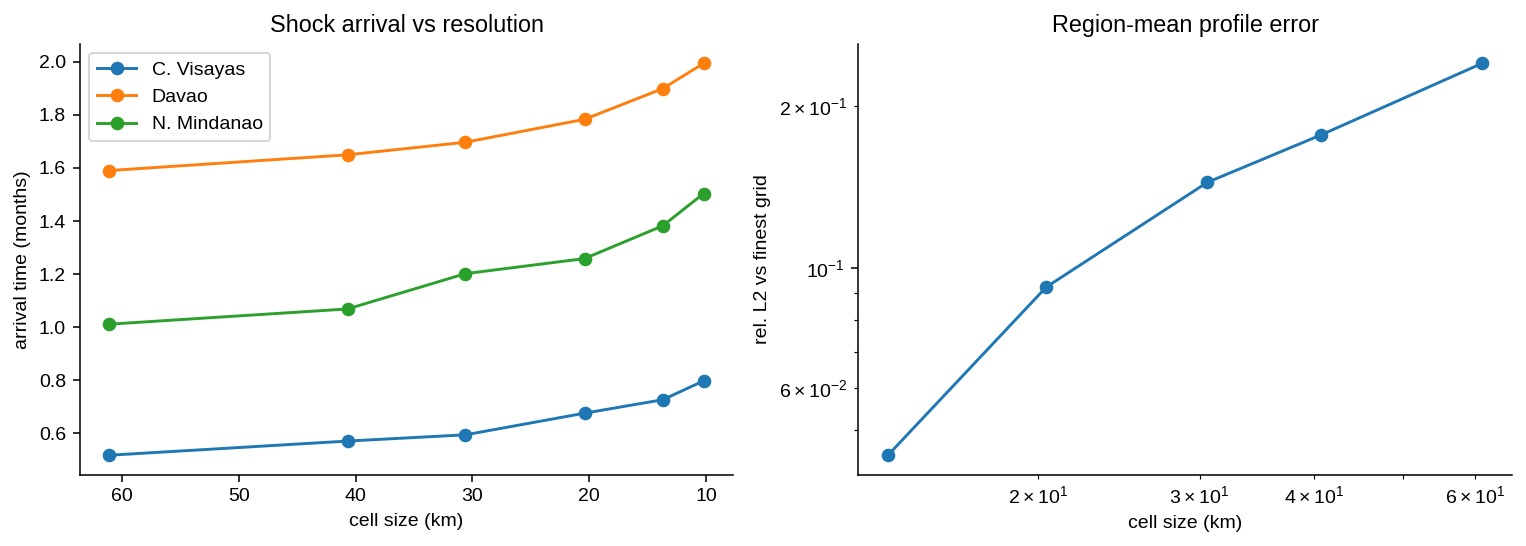

In [ ]:
# ==============================================================================
# ITEM 4: grid-refinement study on the real archipelago at fixed *physical* D, alpha.
# (Temporal convergence is in the verification cell; here dt is small and fixed.)
# ==============================================================================
D_STUDY = float(min(D_USE, 2e4))
res_df, res_profiles = resolution_study(
    ph_gdf, D_STUDY, ALPHA_USE, SEA_RATIO, sizes=[30, 45, 60, 90, 135, 180],
    targets={"C. Visayas": "Central Visayas", "Davao": "Davao", "N. Mindanao": "Northern Mindanao"},
    T=6.0, dt=0.02)
display(res_df.round(4))
err_col = [c for c in res_df.columns if c.startswith("rel_L2")][0]
p_obs = observed_order(res_df, err_col)
print(f"Observed convergence rate in cell size: ~ h^{p_obs:.2f}")
print("Reading: the rate is limited by the *geometry* (the land/sea mask and region borders change with ny), "
      "not by the stencil, which is 2nd order (see the verification cell).")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c in [c for c in res_df.columns if c.startswith("arrival")]:
  ax[0].plot(res_df["cell_km"], res_df[c], "o-", label=c.replace("arrival ", "").replace(" (mo)", ""))
ax[0].invert_xaxis(); ax[0].set_xlabel("cell size (km)"); ax[0].set_ylabel("arrival time (months)")
ax[0].set_title("Shock arrival vs resolution"); ax[0].legend()
ax[1].loglog(res_df["cell_km"][:-1], res_df[err_col][:-1], "o-")
ax[1].set_xlabel("cell size (km)"); ax[1].set_ylabel("rel. L2 vs finest grid"); ax[1].set_title("Region-mean profile error")
plt.tight_layout(); plt.show()

## LLM usage (declare every use and append prompts/outputs)
1. _TODO: list each use as in the proposal — [section] (model) prompt (sources synthesised)._
2. [Notebook review and v2 extension: conservative solver, calibration, coupling, implicit schemes, resolution study] (Claude, Sonnet 5.5) — evaluate our implementation; implement improvements 1–5.